<a href="https://colab.research.google.com/github/sscs-ose/sscs-ose-code-a-chip.github.io/blob/main/ISSCC27/submitted_notebooks/analog_design_difficulty/code_a_chip.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Why Analog Design Remains Difficult Even When the Equations Are Known
### A reproducible SKY130 sample-and-hold case study in coupling, revision, verification, and design closure

| Team member | Affiliation | GitHub |
|---|---|---|
| Kazuki Fujita | Department of Electrical Engineering, Graduate School of Engineering, Tokyo University of Science | 771-8bit |

Licence: Apache-2.0 (`LICENSE`).

## 0. Beyond the Textbook Equations

The equations of a sample-and-hold are in every analog textbook, and this notebook uses them at every step. They are
where the design work starts. What remains is deciding which effects matter, under which conditions, and at what
level of the design a problem should be fixed.

This notebook follows one circuit through that work, from a first formulation to a selected design: a
sample-and-hold front end in the open SKY130 process, simulated with ngspice, in which a closed-loop driver charges a 1 pF
sampling capacitor through a MOS switch in 40 ns, from a 1.8 V supply, for inputs between 0.6 V and 1.2 V. After
a two-point offset and gain calibration at each operating condition, every held sample after start-up must lie within
one 10-bit step of its command, ±0.586 mV.

The circuit did not behave as the textbook picture suggests. The first design met its acquisition-settling
allocation at every nominal test point and still failed the held-sample requirement. Away from nominal it failed
through two unrelated mechanisms at different process, supply, and temperature (PVT) conditions: a switch that
stopped conducting at cold, low supply, and a driver whose input-stage tail transistor left saturation at another
corner. A textbook dummy switch made the turn-off step about five times smaller and the held result worse. The
final circuit, with a bootstrapped switch and a folded-cascode driver, closes the requirement over repeated
samples and 45 PVT conditions at schematic level.


The case is read through a few ideas from analog practice and systems engineering. A requirement can be decomposed
into a tree of allocations, while the physical quantities that must satisfy it form a coupled network with cycles,
whose dependencies change strength with operating point, stored state, and PVT. Engineers make that network
tractable with deliberately incomplete representations — allocations, models, testbenches, block boundaries — and
in this circuit the evidence repeatedly showed where one of them had stopped supporting the decision it served. The practices are established; the
case shows why they exist and how they interact. The notebook then asks what AI changes in this picture, and what a
junior analog designer needs to understand in addition to the equations.

In [1]:
# Setup, no output: locate the repository, load the saved closure result,
# define the figure helpers.
from pathlib import Path
import json
import os
import sys
from IPython.display import SVG, Image, Markdown, display

REPO = Path.cwd().resolve()
while not (REPO / "experiments" / "closure").is_dir() and REPO != REPO.parent:
    REPO = REPO.parent
FIG = REPO / "results" / "figures"
# explanatory drawings
# (scripts/draw_restart_diagrams.py, scripts/draw_diagrams.py)
DIAG = REPO / "assets" / "diagrams"
DATA = REPO / "results" / "data"      # first-cut evidence
# final verification of the selected design
CLOSURE = REPO / "results" / "closure" / "final" / "q1_boot2"
final = json.loads((CLOSURE / "final_closure.json").read_text())

def show(name, width=900):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

def diagram(name):
    display(SVG(filename=str(DIAG / f"{name}.svg")))

## 1. Why analog design remains difficult

The standard results that govern a sample-and-hold are well known: the on-resistance of a MOS switch, the time
constant it forms with the sampling capacitor, the sampled thermal noise `kT/C`, the error of a follower with
finite loop gain, and the charge a switch releases when it turns off (Razavi, 2017; Gray et al., 2009; Carusone et al., 2012). Taken individually, these results do not establish whether the held voltage
will be correct.

The quantities are not independent, and how strongly they depend on one another changes with the conditions of
use. A wider switch lowers the on-resistance, which helps acquisition, but carries more channel charge, which
enlarges the step when the switch opens. A larger sampling capacitor shrinks that step and the `kT/C` noise but
asks the driver for more charge in the same 40 ns; while the switch is closed, switch and capacitor load the
driver's output inside its feedback loop. On-resistance and released charge depend on signal level, supply,
temperature, and process corner, and the voltage held at the end of one sample is where the next one starts.

Behind this condition dependence is MOS nonlinearity. A transistor's transconductance `gm`, output conductance
`gds`, incremental resistance, terminal capacitances, and channel charge, its threshold and body effect, and even
its region of operation all depend on its terminal voltages and on process, supply, and temperature (PVT)
(Razavi, 2017; Gray et al., 2009). Small-signal quantities such as `gm` and `gds` are derivatives at one
operating point; one value does not describe the whole signal range. Even with unchanged connectivity, the
strength of each dependency in the circuit can therefore change with operating point, stored state, and PVT, and
so can the mechanism that dominates the error.

### A requirement tree and a dependency network

A circuit is judged by a requirement at its boundary — here, by the voltage it holds for the circuit that reads
it. To design against it, engineers split the requirement into allocations that can be owned, measured, and
checked one at a time: so much error for settling, so much for the step when the switch opens, and so on. The
result is a hierarchy from the downstream use to a parent function, its parent requirement, and the allocations
below it, the structure systems-engineering practice uses to manage requirements (NASA, 2016; Kundert et al., 2000). Figure 1 shows that tree on the left.

The physical quantities that must satisfy those allocations do not form the same tree (right of Figure 1). The
switch width affects the on-resistance, the channel charge, and the kickback when the switch closes; the
sampling capacitor affects the kickback, the turn-off step, the noise, and the area; the driver's output
impedance affects both acquisition and how the switch's charge divides at turn-off. The effects the allocations
address share these causes and jointly determine the held voltage, and the held error of one sample becomes the
start of the next, which closes a cycle through the stored state. Design-structure analyses describe
such cyclically coupled parameters as groups that no sequential ordering resolves (Steward, 1981; Smith and Eppinger, 1997).

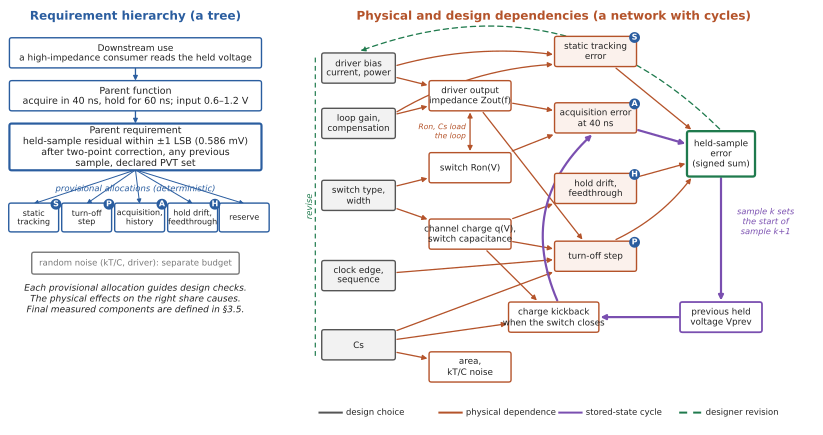

In [2]:
diagram("requirement_vs_network")

*Figure 1. Left: the requirement hierarchy of the running example, down to provisional allocations (S, P, A, H) and a
separate random-noise budget. Right: the physical and design dependencies that must satisfy it — design choices
(grey), circuit quantities and error components (rust, badges match the allocations), and the parent quantity
(green); purple arrows form the stored-state cycle, and the dashed path is a revision driven by evidence at the
parent. A simplified drawing of this circuit (Interpretation), not a complete model.*

Hierarchy can coexist with coupling. Simon argues that many systems are *nearly* decomposable: interactions
within a subsystem are stronger than those between subsystems (Simon, 1962). Whether an interaction
is weak enough to ignore, however, depends on the required accuracy and the conditions, and at one part in a
thousand of the signal range many are not.

Engineers also have established ways to move through a coupled design space: sensitivity analysis shows which
parameters a performance responds to at a design point, structured parameter sweeps map a response over a few
variables, design centering places a design so that it keeps its specifications under process variation, and
numerical and multi-objective optimization search many variables at once (Graeb, 2007; Mukherjee et al., 2000; Rutenbar et al., 2007). These methods make a coupled problem searchable. Each still works on
the variables, objective, model, and verification conditions it is given; Sections 3.4 and 4.3 show what happens
when one of those is the wrong one.

Simulating the complete coupled circuit for every candidate is impractical: the final verification of the design
selected here alone is 5,490 counted samples across 45 PVT conditions, plus stability,
noise, and device-voltage checks (Derived from the closure result in Section 3.5), and a large table of passes and
failures does not say which dependency to change. Engineers therefore use deliberately incomplete representations — a
requirement split into allocations, a model that keeps the effects relevant to one decision, a testbench that
excites one port, a boundary between blocks. They make the coupled problem tractable, and the designer must
recognize when one of them no longer supports the decision being made.

## 2. The running example: a SKY130 sample-and-hold

The running example is a single-ended sample-and-hold front end on a 1.8 V supply in the open SKY130 process
(Figure 2). A closed-loop driver, an operational amplifier connected as a unity-gain follower, receives a command
voltage between 0.6 V and 1.2 V; a MOS sampling switch connects its output to a sampling capacitor `Cs` = 1 pF. The
downstream circuit that reads the held voltage is assumed to have a high input impedance and is not modelled.

A clock repeats every 100 ns. For the first 40 ns the switch is closed and the driver charges `Cs` toward the
command (acquisition); for the remaining 60 ns `Cs` holds the sample while the downstream circuit reads it. The
command for the next sample changes 1 ns after the switch opens, by up to the full range, and the next acquisition
must bring `Cs` from the previous held voltage to the new command within 40 ns. That is the input class the design
is built and verified for; a command that changes exactly as the switch closes is a different class, reported as a
diagnostic in Section 3.5.

When the switch closes, the driver sees the difference between the new target and the previous held voltage on
`Cs` as a sudden charge demand on its output, so the circuit has memory from one period to the next even though
each sample is meant to be independent.

**The requirement applies after calibration.** The input span is 0.6 V, so a 10-bit-equivalent step is `VLSB` =
0.6 V / 1024 ≈ 0.586 mV. The front end is assumed to belong to a system that calibrates it in the foreground at
each operating condition: offset and gain are measured from repeated samples at 0.6 V and 1.2 V and removed by
the straight line through those two points. That calibration is part of the function being verified. It removes
the offset and gain error of the raw held voltage, which drift with process, supply, and temperature; what must
stay within ±1 `VLSB` of the command is the residual after the correction — the error that depends on level,
previous sample, and timing, which a two-point line cannot remove. This is not an absolute-accuracy requirement.

**What the brief freezes and what it treats as cost.** The brief freezes what the argument needs: the input
range, the 40 ns acquisition, the deterministic held-sample accuracy after calibration, a separate random-noise
budget (Section 3.1), behaviour over sequences of samples, and the declared PVT and verification domain with its
stability, model, and device checks. Supply current, device width, added capacitance, and circuit complexity get no
hard limits; they are the costs each design response is judged by and traded against. A product would add explicit
requirements for power, area, interfaces, reliability, and the surrounding system. Keeping them soft here isolates
the notebook's question — how coupled analog errors are formulated, diagnosed, revised, and closed — without making
those resources free.

Each counted sample is read in two windows (Figure 2), and both must pass. The early window, 10–20 ns after the
switch opens, reads the held value after the opening transient: it contains the step the switch leaves when it
opens and, because the next command changes 1 ns after opening, the first coupling of that change through the
open switch's capacitance. The late window, from 6 ns to 1 ns before the next acquisition, is the latest moment a
downstream circuit could use the sample; it adds the droop and feedthrough that accumulate over the hold. Section 3.5 gives the exact measurement, including
how the first cycle after start-up is treated.

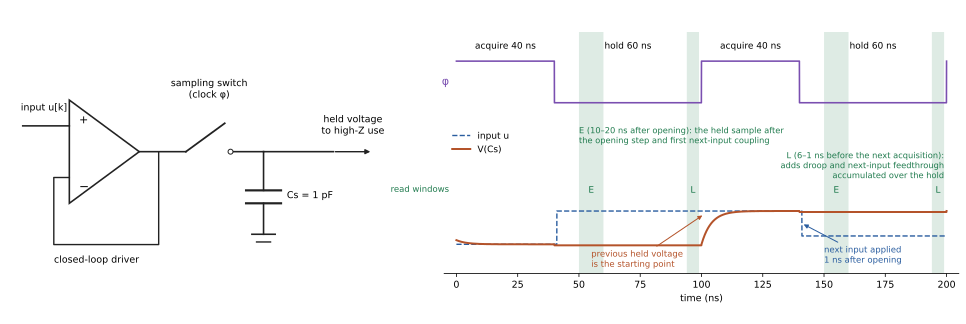

In [3]:
diagram("sampling_cycle")

*Figure 2. The running example. Left: driver (unity-gain follower), sampling switch, `Cs`, and the high-impedance
downstream use. Right: two 100 ns periods of 40 ns acquisition and 60 ns hold, with the next command applied 1 ns
after opening, and the early (E) and late (L) read windows.*


The numbers in the rest of the notebook come from committed SKY130/ngspice results, which the notebook reads; two
cells in Section 3 can optionally rerun their bounded first-cut benches. The cell below reports the tools and PDK
that produced the saved results. Appendix A gives the commands that regenerate every result.

In [4]:
# The SKY130/ngspice simulations are long (first-cut evidence about 12
# minutes; final closure verification of the selected design several hours
# on 12 cores). This notebook reads their committed results;
# scripts/reproduce.py regenerates them (Appendix A).
import platform
import shutil
env = final["environment"]
print("selected design:           ", final["design"])
print("simulator (saved results): ", env["ngspice"])
print("SKY130 PDK (saved results):", env["sky130_sources"], "|",
      env["sky130_library"])
print("Python (saved results):    ", env["python"], "| numpy", env["numpy"],
      "| matplotlib", env["matplotlib"])
print("Python (this kernel):      ", platform.python_version())
print("ngspice on this machine:   ",
      "found" if shutil.which("ngspice")
      else "not found (not needed to read the saved results)")

selected design:            q1_boot2
simulator (saved results):  ngspice-42
SKY130 PDK (saved results): open_pdks c6d73a35f524070e85faff4a6a9eef49553ebc2b | sky130A/libs.tech/ngspice/sky130.lib.spice
Python (saved results):     3.14.6 | numpy 2.5.4 | matplotlib 3.11.2
Python (this kernel):       3.14.6
ngspice on this machine:    found


## 3. Making a coupled analog design tractable

This section follows the sample-and-hold from its first formulation to a selected design. Its subsections are
recurring engineering practices, each paired with the difficulty it addresses and with what the circuit showed;
they are not a fixed sequence, and here several ran at the same time.

### 3.1 Start with a provisional problem

A switch cannot be sized without a number for its on-resistance, which depends on how fast the driver will be,
which depends on the load the switch presents. Design has to start before these quantities exist, from a problem
known to be incomplete. Each quantity in it plays a role. A **parent requirement** comes from the downstream use and changes only
by an explicit decision. A **provisional allocation** (a working target) splits the parent into pieces that can be
designed and checked one at a time. A **design variable** is what the engineer chooses — a topology, a size, a bias
current. A **derived response** follows from the others and must be recomputed when they change.

These are roles in
the current formulation, not properties of the quantities. In the first cut, `Ron` ≲ 1 kΩ was a working target, the
gate width was the design variable chosen to meet it, and the achieved on-resistance was a derived response; in a
reduced model that sweeps `Ron` directly, `Ron` is the design variable. Making the roles explicit tells the engineer
what new evidence is allowed to revise: a missed allocation can be re-split, while the parent changes only by
decision. Reformulating the problem can change the roles, as the redesign below does.

The first cut split the parent into an acquisition-settling allocation ε = 0.29 mV, about half of `VLSB`, and a
level-dependent remainder of ½ `VLSB`, shared equally between switch turn-off and driver static tracking.
Settling 0.6 V to ε takes ln(0.6 V/ε) ≈ 7.6 time constants, so 40 ns allows about 5.3 ns in total; about one
fifth went to the switch, so `Ron` ≲ 1 kΩ at 1 pF. The switch was the smallest CMOS transmission gate, in 5 µm
steps, that met 1 kΩ over the range; the driver an existing two-stage Miller amplifier at 130 µA; sampled noise
was `kT/C` alone. 

A hand estimate flagged the switch: the 15 µm NMOS device holds roughly `W·L·Cox·(VDD − V − Vt)` ≈ 2.25 µm² × 8
fF/µm² × 0.7 V ≈ 13 fC near 0.6 V, and if about half reaches 1 pF the held voltage moves by several millivolts, an order of magnitude above `VLSB`
(Wegmann et al., 1987), with the PMOS charge of opposite sign making the step level-dependent.
Most of that step is offset and gain, which the correction removes, so whether the residual exceeds `VLSB` was a
question for simulation. *(Derived.)*

| Statement | First cut | Redesign |
|---|---|---|
| Downstream use | a high-impedance circuit reads the held voltage once per 100 ns period | same |
| Parent function | hold the command voltage (0.6–1.2 V) on `Cs`, non-inverting | same |
| Parent requirement (fixed) | ±1 `VLSB` after two-point correction | same |
| Verification of the parent | nominal, `Cs` precharged to the target | repeated samples and sequences, 45 PVT conditions, two read windows |
| Provisional allocations | acquisition ε = 0.29 mV; turn-off 0.15 mV; static tracking 0.15 mV; switch `Ron` ≲ 1 kΩ; random: `kT/C` | `R_S` 0.15, `R_P` 0.15, `R_A` 0.10, `R_H` 0.10, reserve 0.086 mV; random ≤ 0.25 `VLSB` rms, separate |
| Design variables | two-stage Miller driver, 130 µA; CMOS transmission gate 15/30 µm; `Cs` = 1 pF; 0.2 ns edges | Section 3.4 |
| Derived responses | `VLSB` = 0.586 mV; 7.6 time constants to settle 0.6 V to ε, 5.3 ns total in 40 ns; `kT/C` = 64 µV rms | same `VLSB`; `kT/C` 57–74 µV over −40 to 125 °C |

*Table 3.1. The provisional problem of the first cut and of the redesign, by the role of each statement.*


The redesign kept the parent but changed how it was checked — real repeated samples and sequences instead of a
capacitor precharged to the target, 45 PVT conditions instead of nominal and two corners, a late read window — and
moved acquisition error from a separate allocation into the held-sample metric. Its allocation names each term by
the part of the cycle in which it acts (Figure 3): `R_S`, static tracking before the switch opens; `R_P`, the
level-dependent part of the step at opening; `R_A`, what remains of the charge kick at closure and of the driver's
state from the previous sample; `R_H`, droop and coupling of the next command through the open switch during the
hold. A reserve covers PVT spread and model and numerical uncertainty; random noise has its own budget, 0.25 `VLSB` rms
(146 µV), never added into the deterministic residual. In the text, a capital `R` names a provisional
allocation; the components measured in the final verification are written in lower case (`r_S`, `r_P`, `r_H`) and
defined in Section 3.5.

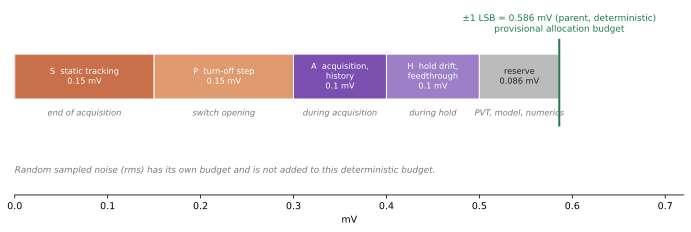

In [5]:
diagram("budget_phases")

*Figure 3. The provisional ±1 `VLSB` budget placed on the sampling cycle: `R_A` after the switch closes, `R_S` during
acquisition, `R_P` at opening, `R_H` during the hold. Random noise is a separate budget. The allocations are
diagnostic; only the parent residual is pass/fail.*

The allocations tell the designer where to look; they do not decide whether the design passes, and specifications
passed down a hierarchy have to be informed by what the lower levels can achieve
(Rutenbar et al., 2007). The budget adds magnitudes, while the physical effects can partly
cancel in the held voltage. And margin consumes resources: because current, width, and capacitance are costs rather
than limits here (Section 2), tightening a local entry is never free — more loop gain costs current, headroom, or
compensation capacitance, and a smaller switch step costs conduction — and minimizing every local entry can spend
resources the parent result does not need. Section 3.4 shows both effects on a design decision.

### 3.2 Characterize where the first cut holds

The first cut passed its acquisition allocation at every nominal test point and still failed the parent
requirement. At `tt`, 27 °C, 1.8 V it met the allocation at all nine combinations of target and previous voltage in
{0.6, 0.9, 1.2} V: worst error at 40 ns 0.011 mV against ε = 0.29 mV, last crossing of ε at 29.7 ns. The
full-scale transitions also passed at `ss` and `ff`, 27 °C. Yet with `Cs` precharged to the target and seven held levels, the level-dependent residual after the
two-point correction was 0.64 mV, above `VLSB` (0.586 mV) by itself. *(Observed.)* 

The sequential bench of the final verification (Section 3.5), in which each held sample is the starting state of
the next, evaluated the first cut at seven screening conditions, a reduced set used to assess candidates before
final verification (Figure 4). At nominal it gives the same number from a different bench, 0.645 mV (1.10
`VLSB`); with the command changing during the hold, the previous sample changes the residual by only 0.014 mV.
Away from nominal, two different mechanisms fail at two different places. At −40 °C and the low supply, with `ss` and `sf` devices, the residual is 115 mV and 46 mV (196
and 78 `VLSB`). There the transmission gate stops conducting at mid-scale: with about 0.7–0.9 V of gate drive on
each device and body-raised thresholds of similar size, neither device is on; the worst on-resistance reaches 127
kΩ at 0.90 V (`ss`, 1.62 V, −40 °C), and acquisition does not finish. At the `fs` corner, at −40 °C and low supply
and at 125 °C and high supply, the residual is 1.14 and 2.04 `VLSB` with the switch conducting normally. There the
driver's static tracking error reaches about 1 mV: with a 0.6 V input, the tail transistor of the low-threshold
input pair is pushed into triode, so the tail current — and with it the amplifier's systematic offset — changes
with signal level, and the amplifier's modest DC open-loop gain (42–57 dB) does not suppress it. Two conditions
pass (`ff` and `sf` at 1.98 V, 125 °C, with 0.69 and 0.96 `VLSB`). *(Observed.)*

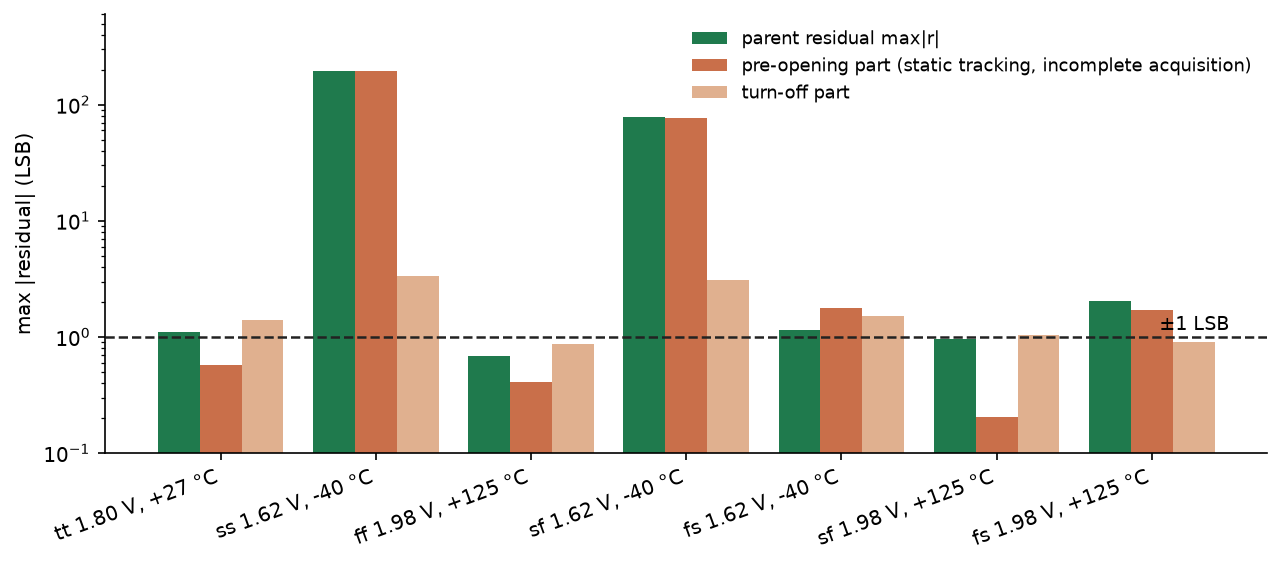

In [6]:
show("figure_f2_screening_map")

*Figure 4. The first cut on the sequential bench at the seven screening conditions: largest parent residual (green)
and its pre-opening and turn-off parts, in `VLSB` (log scale; dashed line 1 `VLSB`). The transmission-gate conduction
gap (`ss`/`sf`, −40 °C, 1.62 V) and the driver's tail headroom (`fs`) fail at different corners. Screening supplies
were 1.62 V and 1.98 V; the final set uses 1.60 V and 1.95 V.*

Three things follow. Meeting an allocation at every tested point does not show that the parent requirement is
met. The first cut had been checked at nominal for the held sample and at two room-temperature corners for
acquisition, a small part of the domain the requirement covers, and the worst cases lay outside it. And **no single corner is worst for every mechanism compared here**: the
switch fails at cold and low supply, the driver at the `fs` corner, and later candidates showed settling problems
at hot and low supply. A matrix pruned to the corner that is worst for one mechanism would miss the others, which
is why the final verification runs all 45 combinations of five process corners, three supplies, and three
temperatures. 

The failures sit in different places because each condition changes which physical effect matters. The signal
level moves a switch's gate overdrive, and so its on-resistance and channel charge; in a follower it also moves the
amplifier's input common-mode voltage, which pushed the first cut's tail into triode. The previous held voltage
sets the charge the driver must supply when the switch closes; the switch and clock state decide whether `Cs`
loads the driver at all, the edge times how channel charge divides at opening, and the command timing whether
the driver is still settling when the switch closes. Process, supply, and
temperature shift thresholds, mobilities, and headroom, which closed the transmission gate's conduction window at
cold, low supply. An interaction that was negligible where the first cut was checked can dominate elsewhere.

The engineering response is to replace "what is the number?" by "over which conditions does this named
requirement hold?", reading the result as a pass/fail region on a stated grid, as long-standing practice in analog
design automation does for operating ranges and process variation (Mukherjee et al., 2000; Graeb, 2007). A grid of representative points is not a continuous sweep: the turn-off residual of the first-cut gate peaks
near 1.0 V, between the 0.9 V and 1.2 V points of a three-level grid, which is why the held-sample checks use
seven or more levels.

### 3.3 Let implementation expose what the first cut missed

The first cut's driver was designed against a representation of the switch, not the switch itself: `Cs`, the
voltage range, 40 ns, and one linear resistance `R_if` = 744 Ω, the transmission gate's largest DC on-resistance
over the range. For transitions it was adequate or conservative: the driver settled up to 2.3 ns later against `R_if` than
against the real gate, so for inputs that may start from any previous voltage no acquisition allocation passes the
block test and fails the connected circuit. In a fixture where `Cs` starts exactly at the target, the same
representation was badly misleading: it supports an acquisition of 0.8 ns where the connected circuit needs 10.3 ns
(Figure 5). The resistance omits the turn-on event: when the switch closes,
its complementary gate edges couple charge into the driver output (+26 mV at 0.6 V, +14 mV at 0.9 V, −30 mV at 1.2
V), a capacitive path the resistor does not contain. With the same driver, switch, and simulator, the
representation is adequate for one decision and inadequate for another; what changes is the input class and the
allocation. *(Observed, first cut.)*

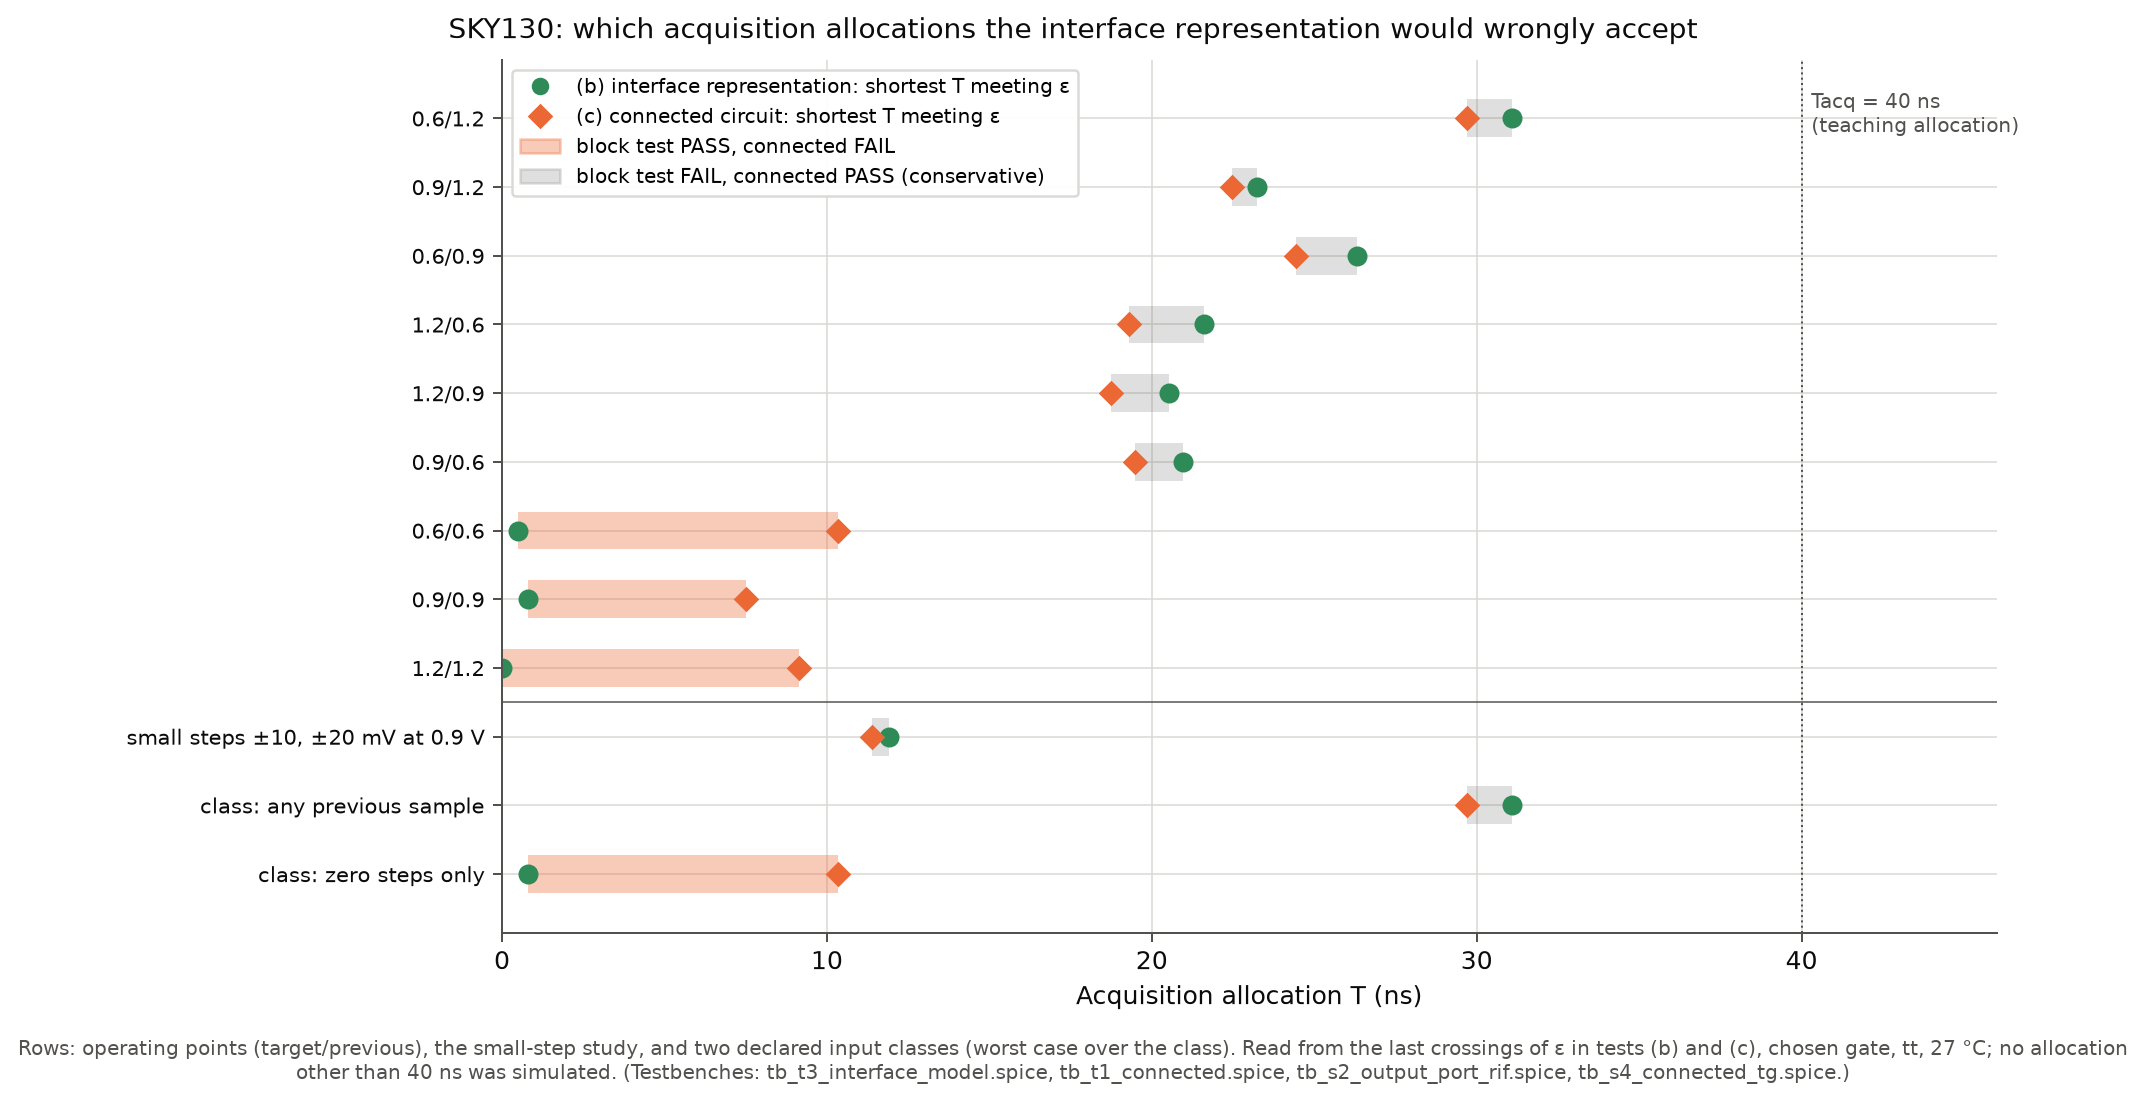

In [7]:
show("figure_sky130_acquisition_window")

*Figure 5. First cut, `tt`, 27 °C: shortest acquisition interval supported by the block test with `R_if` and needed
by the connected circuit, at each operating point. Conservative for transitions; in the zero-step fixture the block
test accepts intervals between 0.8 and 10.3 ns that the connected circuit rejects.*

**Try it.** The cell below compares, for one previous/target pair, the driver's block test with an input step, the
driver loaded by `R_if` and excited at its output port, and the connected circuit with the real gate, and prints
when each error last exceeds ε. Equal `PREVIOUS` and `TARGET` give the zero-step case of Figure 5; 0.6 and 1.2 give a
transition, where the input-step and output-port tests also differ (Section 3.5). `SOURCE = "spice"` reruns these
benches instead of reading the saved waveforms.

output port + R_if   last |error| ≥ ε at 0.45 ns
connected TG         last |error| ≥ ε at 10.30 ns


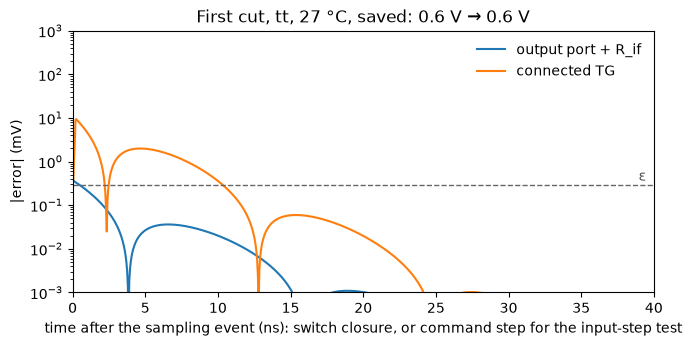

Times are read from the saved 50 ps grid; Figure 5 uses the full-resolution waveforms.


In [8]:
# Try it: one acquisition of the first cut (tt, 27 °C) from PREVIOUS to
# TARGET (each 0.6, 0.9 or 1.2 V) on up to three benches.
# SOURCE = "saved": the committed waveforms behind this notebook (default).
# SOURCE = "spice": rerun only these benches (needs ngspice and SKY130A;
# about a minute; output goes to a temporary folder, not to results/).
SOURCE = "saved"
PREVIOUS, TARGET = 0.6, 0.6
# any of: "input step", "output port + R_if", "connected TG"
BENCHES = ["output port + R_if", "connected TG"]

import csv
import numpy as np
import matplotlib.pyplot as plt
EPS = 0.6e3 / 1024 / 2   # acquisition allocation ε of the first cut, mV
traces = {}   # bench -> (time in ns, error in mV)
if SOURCE == "spice":
    sys.path.insert(0, str(REPO / "experiments" / "experiment_a" / "sky130"))
    import interactive
    traces = interactive.excitation(PREVIOUS, TARGET, BENCHES)
else:
    CODE = {"input step": ("a", "out"), "output port + R_if": ("b", "samp"),
            "connected TG": ("c", "samp")}
    with open(DATA / "sky130_waveforms_tt.csv") as fh:
        rows = list(csv.reader(fh))
    head, wav = rows[0], np.array(rows[1:], dtype=float)
    for bench in BENCHES:
        test, node = CODE[bench]
        col = f"{test}_{TARGET:.1f}_{PREVIOUS:.1f}_{node}_err_mV"
        if col in head:
            traces[bench] = (wav[:, 0], wav[:, head.index(col)])
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for bench in BENCHES:
    if bench not in traces:
        print(f"{bench:20s} not run for this pair "
              "(the input-step test needs a change of command)")
        continue
    t, err = traces[bench][0], np.abs(traces[bench][1])
    keep = (t >= 0) & (t <= 40) & ~np.isnan(err)
    above = np.flatnonzero(keep & (err >= EPS))
    last = f"{t[above[-1]]:.2f} ns" if above.size else "never above ε"
    print(f"{bench:20s} last |error| ≥ ε at {last}")
    ax.semilogy(t[keep], np.maximum(err[keep], 1e-4), label=bench)
ax.axhline(EPS, color="0.4", ls="--", lw=1)
ax.text(39.5, EPS * 1.25, "ε", ha="right", color="0.3")
ax.set_xlabel("time after the sampling event (ns): switch closure, "
              "or command step for the input-step test")
ax.set_ylabel("|error| (mV)")
ax.set_title(f"First cut, tt, 27 °C, {SOURCE}: {PREVIOUS} V → {TARGET} V")
ax.set_xlim(0, 40)
ax.set_ylim(1e-3, 1e3)
ax.legend(frameon=False)
plt.show()
if SOURCE != "spice":
    print("Times are read from the saved 50 ps grid; "
          "Figure 5 uses the full-resolution waveforms.")

A model can be adequate for one decision and inadequate for another without being wrong in a universal sense. The
omission was invisible inside the representation and appeared only when the real switch was connected — as
omissions do when more of the physical circuit is included: the actual neighbour instead of a model, excitation at
the port where the real disturbance enters, transistor detail, stored state propagating from sample to sample.
Mixed-signal practice runs connected and mixed-level
tests because an isolated testbench may not reproduce the loading and signal sequences of the connected system
(Kundert et al., 2000; Chang and Kundert, 2007). Read more broadly, the physical implementation and
the composition of blocks are themselves a source of design knowledge, not only a check of decisions already made
*(Interpretation)*. Shared supply and ground impedance, the substrate, and the package are further paths in a real
layout; the benches here use ideal supply and ground and no substrate or package network, so this study does not
exercise them.

The circuit produced three further exposures.

The redesigned switch (Section 3.4) produced one. Its first bootstrapped variant charged the boost capacitor
through a PMOS device. On the sequential bench, the same target held after a 0.6 V and after a 1.2 V sample differed
measurably. At turn-on the charging device was still conducting while the boost capacitor's bottom plate began to
follow the input node, which the previous charge on `Cs` had kicked, so the boost charge, and with it the gate
drive, depended on the previous sample. Charging the capacitor through a clock-boosted NMOS that turns off first
removed most of the effect. A fixture that precharges `Cs` to the target cannot show this dependence by
construction. *(Observed.)* 

Noise was the next. The first cut counted sampled noise as `kT/C`, 64 µV rms at 1 pF; with the driver included,
the noise on `Cs` was about 263 µV rms (Table B.1), four times larger: the driver's white noise extends over its closed-loop bandwidth of roughly 50–100 MHz, and `Cs` samples all
of it. For the later driver candidates this term, not `kT/C`, decided
the noise budget. *(Observed.)* 

The last sat inside the driver. A redesigned driver settled a full-scale step to 0.05 mV only after about 100 ns,
and even a 10 mV step left a 0.2 % error at 40 ns. Bypassing nodes one at a time found the path: the output swing
coupled through the gate-drain capacitance of the large output sink transistor into the shared bias line (about 3
pF and 4 kΩ, τ ≈ 12–15 ns), which modulated the tail and sink currents. Biasing the
sink device from its own diode removed the path (settling of a full-scale command step to 0.05 mV in 46–61 ns,
with the command applied at the start of the hold). A bias line drawn as one node was a shared impedance between a
precision current source and a large output device. *(Observed.)* 

Each exposure revised something different: an interface representation and the input class it may be used for, a
switch circuit, a budget's noise estimate, and a bias network. None could appear inside the representation that
omitted it. When a connected test, a different excitation port, or propagated state reveals an
omitted interaction, the designer must decide whether to change the circuit or the representation.

### 3.4 Respond at the right level

A failed parent result rarely says what to change — a requirement or allocation, an operating condition, a
transistor size, the circuit of one block, the functional structure of the front end, a model, the verification, or
how much of the circuit is designed jointly — and a change at the wrong level can improve a local number while the
parent result stays put or gets worse. Here the response went through three stages.

#### A local improvement can worsen the parent

Half-size dummy switches, the textbook remedy for the turn-off step (Eichenberger and Guggenbühl, 1990), reduced the
uncorrected hold step about fivefold but its level-dependent part only 1.8-fold (0.83 → 0.46 mV), and the parent
residual got worse (0.64 → 0.78 mV). The gate's negative turn-off residual had been partly cancelling the driver's
positive static residual; the dummies changed its sign over 0.7–0.9 V, so the two added.

In a width ladder the turn-off residual scaled almost exactly with width (0.09, 0.20, 0.38, 0.83, 1.91 mV from one
eighth to double width), while the worst acquisition moved only from 29.7 to 32.2 ns: the 1 kΩ on-resistance
allocation had restricted the switch more than this driver needed. By the local turn-off share the narrowest gate
was best; by the signed parent residual at nominal, half width (0.19 mV) ranked ahead of quarter (0.23 mV) and
eighth (0.27 mV) (Figure 6). The half-width pass rested on two physically unrelated errors — a driver headroom
effect and a switch threshold effect — having opposite signs at `tt`, 1.8 V, 27 °C; the narrower gates' turn-off
residuals were small enough not to need that cancellation. *(Observed, first cut.)*

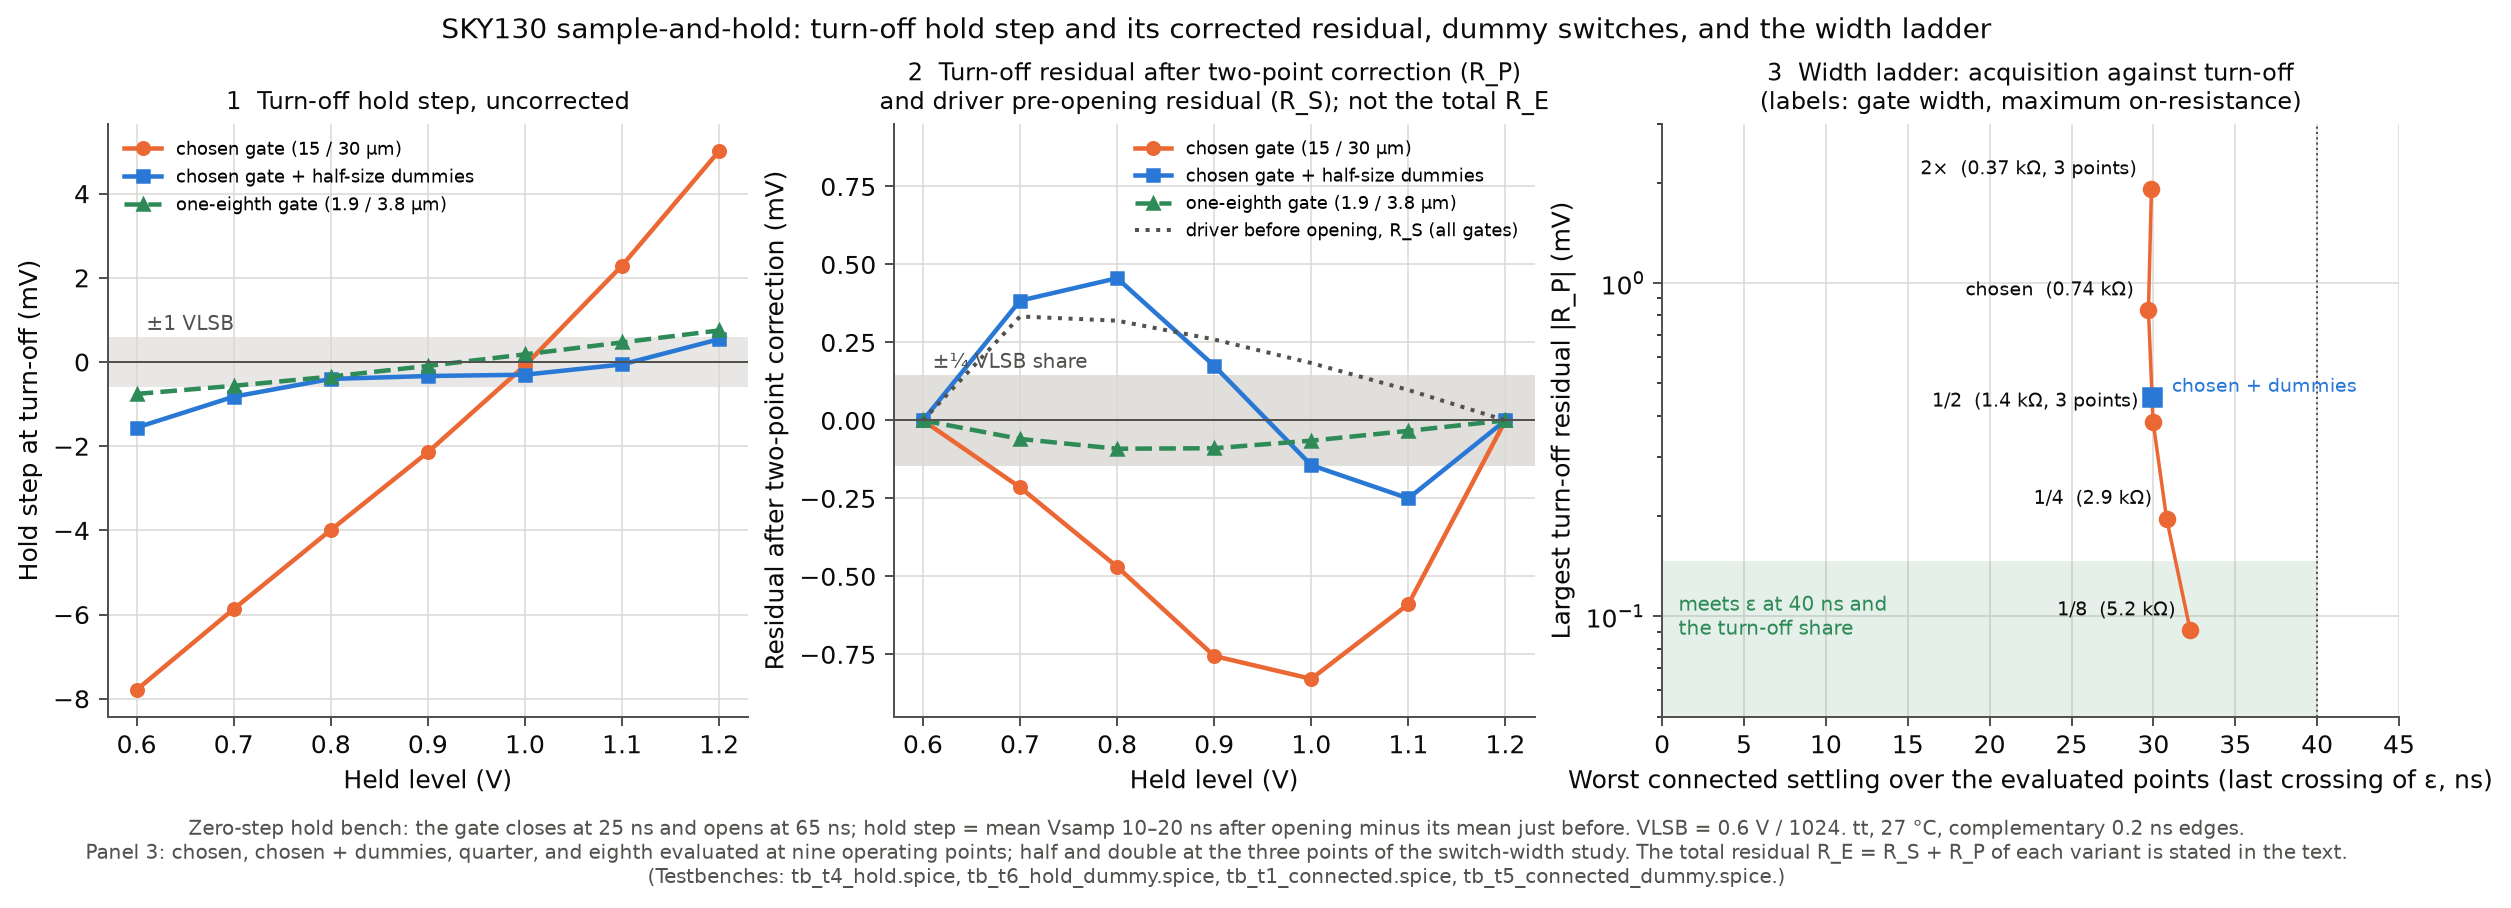

In [9]:
show("figure_sky130_held_sample")

*Figure 6. Turn-off step and corrected residual of the first-cut gate, the gate with dummies, and the width ladder
(`tt`, 27 °C, zero-step bench). The figure's `R_P` and `R_S` are that bench's turn-off and pre-opening components, not
the allocations of Figure 3 or the final components of Section 3.5. The signed parent residual of each width is ranked
in the cell below.*

**Try it.** `METRIC = "local"` ranks the five widths and the dummy variant by the largest turn-off residual, which
the turn-off allocation constrains; `METRIC = "parent"` ranks them by the largest held-sample residual after
correction, which the requirement constrains. `SOURCE = "spice"` reruns the hold bench for all six variants instead
of reading the saved results.

ranked by local metric (best first); limits: turn-off share 0.146 mV, parent 0.586 mV
    variant                 local (mV)  parent (mV)
1   1/8 width                    0.091        0.274
2   1/4 width                    0.196        0.228
3   1/2 width                    0.384        0.189
4   first cut + dummies          0.456        0.776
5   first cut (15/30 µm)         0.828        0.645
6   2× width                     1.913        1.729


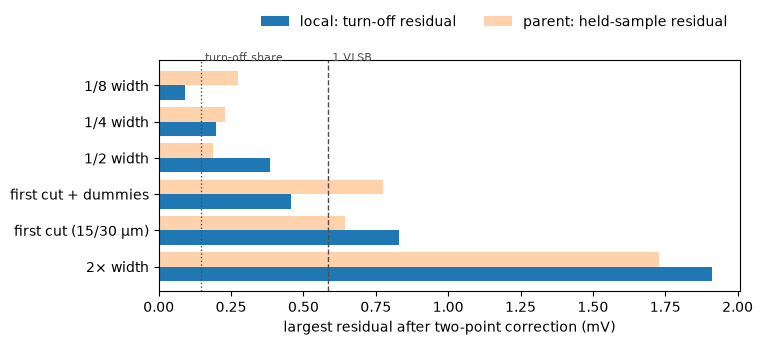

Nominal zero-step bench only. Over PVT the 1/2-width gate reaches 296 VLSB at ss, -40 °C, 1.62 V (text below).


In [10]:
# Try it: rank the first-cut gate variants (tt, 27 °C, zero-step bench)
# by a local or by the parent metric.
# "local": largest corrected turn-off residual
# "parent": largest held-sample residual after correction
METRIC = "local"
# SOURCE = "saved": the committed width-ladder results (default).
# SOURCE = "spice": rerun the hold bench for all six variants (needs ngspice
# and SKY130A; a few minutes on several cores; temporary folder).
SOURCE = "saved"

import matplotlib.pyplot as plt
if SOURCE == "spice":
    sys.path.insert(0, str(REPO / "experiments" / "experiment_a" / "sky130"))
    import interactive
    hs = interactive.width_ladder()
else:
    summary = DATA / "sky130_followup_summary.json"
    hs = json.loads(summary.read_text())["held_sample"]
NAMES = {"eighth": "1/8 width", "quarter": "1/4 width", "half": "1/2 width",
         "chosen": "first cut (15/30 µm)", "double": "2× width",
         "dummy": "first cut + dummies"}
LOCAL, PARENT = "max_residual_hold_step_mV", "max_residual_held_error_mV"
key = {"local": LOCAL, "parent": PARENT}[METRIC]
order = sorted(NAMES, key=lambda n: hs["variants"][n][key])
print(f"ranked by {METRIC} metric (best first); "
      f"limits: turn-off share {hs['share_mV']:.3f} mV, "
      f"parent {hs['VLSB_mV']:.3f} mV")
print(f"{'':4s}{'variant':22s}{'local (mV)':>12s}{'parent (mV)':>13s}")
for i, n in enumerate(order, 1):
    v = hs["variants"][n]
    print(f"{i:<4d}{NAMES[n]:22s}{v[LOCAL]:12.3f}{v[PARENT]:13.3f}")
fig, ax = plt.subplots(figsize=(7.5, 3.0))
y = range(len(order))
ax.barh([i + 0.2 for i in y], [hs["variants"][n][LOCAL] for n in order],
        height=0.4, label="local: turn-off residual",
        alpha=1.0 if METRIC == "local" else 0.35)
ax.barh([i - 0.2 for i in y], [hs["variants"][n][PARENT] for n in order],
        height=0.4, label="parent: held-sample residual",
        alpha=1.0 if METRIC == "parent" else 0.35)
ax.axvline(hs["VLSB_mV"], color="0.3", ls="--", lw=1)
ax.text(hs["VLSB_mV"], -0.6, " 1 VLSB", color="0.3", va="bottom",
        fontsize=8)
ax.axvline(hs["share_mV"], color="0.3", ls=":", lw=1)
ax.text(hs["share_mV"], -0.6, " turn-off share", color="0.3", va="bottom",
        fontsize=8)
ax.set_yticks(list(y))
ax.set_yticklabels([NAMES[n] for n in order])
ax.invert_yaxis()
ax.set_xlabel("largest residual after two-point correction (mV)")
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1.0, 1.08),
          ncol=2)
plt.show()
print("Nominal zero-step bench only. Over PVT the 1/2-width gate reaches "
      "296 VLSB at ss, -40 °C, 1.62 V (text below).")

The cancellation did not survive the declared domain: at `ss`, −40 °C, 1.62 V the half-width gate's residual was
296 `VLSB`, because the conduction gap of Section 3.2 is worse for a narrower switch, and the narrowest gate cannot
conduct there either (Derived). The width ladder is a small, manual instance of the search methods of Section 1;
the objective it is ranked by matters independently of how the search is done. 

#### Change the dependency, not only the value

A characteristic analog response is to change the circuit so that a troublesome dependency becomes weaker, moves to
a node where it matters less, or cancels. Negative feedback divides output impedance and open-loop sensitivity by
roughly one plus the loop gain, at the cost of loop-gain, bandwidth, and stability requirements
(Black, 1934; Razavi, 2017); buffers, differential structures, and switch and clock structures
reshape impedance, common disturbance, or signal-dependent switch error, each at its own cost (Gray et al., 2009; Carusone et al., 2012); the sample-and-hold itself holds a moving input constant for the circuit that
reads it. Feedback and the sample-and-hold are functional structures; bootstrapped switches and folded-cascode first
stages change the circuit within a block.

Resizing the transmission gate could not escape its trade-off. For a given device type the product of channel
charge and on-resistance is roughly fixed, so a turn-off residual near 0.1 mV at 1 pF needs several kilohms, while
conduction at cold and low supply needs more gate drive or width. A gate of low-threshold devices removed the
conduction gap (worst on-resistance 0.83 kΩ) but, with the longer PMOS that device requires, doubled the turn-off
residual (1.66 mV at `tt` with an ideal driver). Both failures have one cause: the switch's conductance and its
channel charge both depend on `VDD − Vin − Vt(Vin)`. *(Observed; Derived.)* 

A bootstrapped NMOS switch substantially reduced that dependency instead of trading along it. Charged to the
supply during hold and placed between gate and source during acquisition, its capacitor keeps `Vgs` near `VDD`
whatever the input level. On-resistance became nearly flat (within 8 % over the range at nominal; at most
0.92 kΩ for the 2 µm switch over the PVT conditions screened before the final supply set) and the channel charge
nearly level-independent, so the turn-off step became mostly an offset that the two-point correction removes (in
the selected design the total offset is -3.2 to -1.2 mV over the declared conditions, and the gain error
-0.9 to 0.0 mV/V, against 20 mV/V for the first-cut gate). The measured opening component `r_P` — the corrected
residual increase from pre-opening to early hold, including next-command coupling — stays at or below 0.011
mV over the whole final verification set (Section 3.5). The technique is established (Abo and Gray, 1999; Razavi, 2015); here it cost ten extra devices, a 0.2 pF bootstrap capacitor and two 50 fF booster
capacitors (about 150 µm² of MIM area), roughly 1 µA, a larger charge kick into the driver at turn-on, and gate
voltages above `VDD` relative to the substrate (Section 3.5). 

The driver needed a response of the same kind. At a 0.6 V input its tail transistor's drain-source voltage is the
input minus the pair's gate-source voltage, which leaves it in triode at most conditions, and no resizing met 0.15 mV
together with the stability and saturation criteria, because one headroom window, `VDD − 0.6 V` = `Vsg` of the PMOS
mirror + tail `Vds` + pair `Vds` at 1.2 V, had to hold at 1.62 V and −40 °C. A folded-cascode first stage puts the
pair's drains near `VDD` instead of a mirror's `Vsg` below it and raises the first-stage gain by about 30 dB; a
native-threshold input pair (`nfet_03v3_nvt`, near-zero `Vt`) leaves the tail several hundred millivolts at a 0.6 V
input; the output sink got its own bias (Section 3.3). The static residual fell from 1.10 mV to at most 0.03 mV over
45 conditions (DC, earlier supply set). With the first-cut gate, however, the improved driver raised the parent
residual at nominal from 1.10 to 1.50 `VLSB`: the nominal result had relied on driver/switch cancellation, and the
switch now had to close its own share. *(Observed.)* 

#### Close the remaining trade-off

The folded cascode introduced a noise problem. Its loads are noisier than a mirror, and in a Miller follower the
sampled first-stage noise behaves roughly like a noise factor times `kT/Cc`; lower noise favors a larger `Cc`, a
full-scale slew a large ratio of tail current to `Cc`, and at 1.60 V headroom limits the current the folding and
mirror devices can carry while saturated. The first folded-cascode driver held
the pre-opening residual at or below 0.022 mV, but its noise on `Cs` was about 745 µV at `tt`, five times the 146 µV
budget; a single-stage alternative missed the noise budget and the stress step defined below (Appendix B). Scaling the folded cascode with a larger `Cc`, an output capacitor, and more
current brought noise close to the budget but slowed the full-scale command response. 

That slower response shows up when a command steps exactly as the switch closes, so that the driver must slew 0.6
V and absorb the charge kick in the same 40 ns. Human review reclassified this **stress timing** from the pass/fail
set to a reported diagnostic before final verification, because the frozen parent function specifies the
**primary timing**, with the command changing during the hold (Appendix B). It remains run and reported, outside the
verified input class (Section 3.6).

A final refinement adjusted existing component values in the scaled driver: a larger `Cc` and output capacitor for
noise, and wider mirror cascodes with a shorter bias diode to restore cold, low-supply headroom. It met the 146 µV
budget under the corrected method (worst 136 µV), so a relaxed fallback declared beforehand was not
used. Its pre-opening residual (static tracking plus what is left of acquisition from the previous sample) stays at
or below 0.090 mV, and it draws 785 µA at `tt` (623–979 µA over the declared set). One
margin narrows: with a 1.2 V input at the slow-NMOS hot corner and 1.60 V, the native input pair, which shares the
top-of-range headroom with the folding sources, sits 31 mV above its saturation edge instead of the 50 mV
target; it stays saturated, and the parent residual there is 0.14 `VLSB`. *(Observed.)*

Both bootstrapped switch sizes, 2 µm and 5 µm, closed with this driver at screening level; the selected design uses
the smaller (0.2 pF bootstrap capacitor), since extra width and boost loading bring no demonstrated benefit once both
pass. Its deterministic margin is large because the current was set by the noise
budget and settling at the slow, hot corners, not by the ±1 `VLSB` requirement; how far the current could be lowered
before one of those binds was not explored.

| Selected design | Current at `tt` | Deterministic, final set | Noise, final set | Cost |
|---|---:|---|---|---|
| scaled folded cascode (refined) + bootstrapped switch W 2 µm | 785 µA | 0.15 `VLSB` worst (fs_1.60V_+125C) | 136 µV worst | 22 + 12 transistors; ideal `Cc` 5 pF, output 4 pF, bias filters |

The decisive changes weakened the troublesome dependencies themselves; local switch or driver tuning alone had not
closed the design, and the last trade-off was closed within the scaled driver without raising its current, against
an unchanged parent requirement.

### 3.5 Ask what evidence is sufficient for this decision

Running every test at full fidelity for every decision is impractical (Section 1). The question is what evidence is
sufficient for the decision being made now: a model adequate to show that a mechanism exists can be inadequate to
size against it, and a test adequate to size a block can be inadequate to freeze it. Here the evidence formed a
ladder; each rung costs more than the one above and answers a question the one above cannot.

| Question behind the decision | Evidence that was sufficient here | What it showed |
|---|---|---|
| Does the mechanism exist at all? | a reduced analytical model, qualitative | input-step and output-port excitation are equivalent for a one-state driver, not for a driver with one internal state |
| Does it matter in this transistor circuit? | a transistor-level test that excites the right port | the port difference survives in the SKY130 driver without slewing (Figure 7) |
| Do history and composition matter? | a sequential bench in which each held sample starts the next | a previous-sample dependence of the first bootstrapped switch (Section 3.3) |
| Does the result hold over the declared domain? | the parent metric over 45 PVT conditions and four sequences | the worst case and margin per condition (Figure 8) |
| Can the design be frozen? | numerical, stability, noise, device-voltage, and no-cancellation checks | that the pass is credible (Table 3.5) |

*The evidence ladder used in this design.*

In the reduced model, a driver with one internal state gives the two excitations the same closed-loop poles but
different numerators (`(1 + Ae)` for the input, `Rout(τd·s + 1)` for the output port) and different initial
internal states; no switch charge, parasitic, or particular topology is needed. The model is qualitative and not
fitted to the SKY130 driver; its numbers are not predictions of the transistor circuit. *(Derived.)* 

Transistor-level SPICE is higher-fidelity for the behavior in the netlist but remains a representation: its
evidence is bounded by the nonlinear compact models, their documented domain, included parasitics, PVT conditions,
idealizations, and numerical assumptions (Vogt et al., 2024; SkyWater Technology Foundry and Google, 2020), and working within that domain
does not guarantee silicon accuracy. With ±10 mV and ±20 mV steps at 0.9 V and the switch represented by `R_if`, the
normalized difference between the first-cut driver's input-step and output-port responses was 0.53 at all four
steps, with first-stage current imbalance below 0.22 (no slewing) and normalized waveforms agreeing within 0.012
across amplitudes (Figure 7). The port difference therefore exists in the approximately linear regime; the
full-scale values, 0.86 and 0.79, add a large-signal contribution. An input-step test cannot certify recovery from
the sampling capacitor's charge kick; the sequential bench excites the driver output as the real circuit does.
*(Observed, first cut.)*

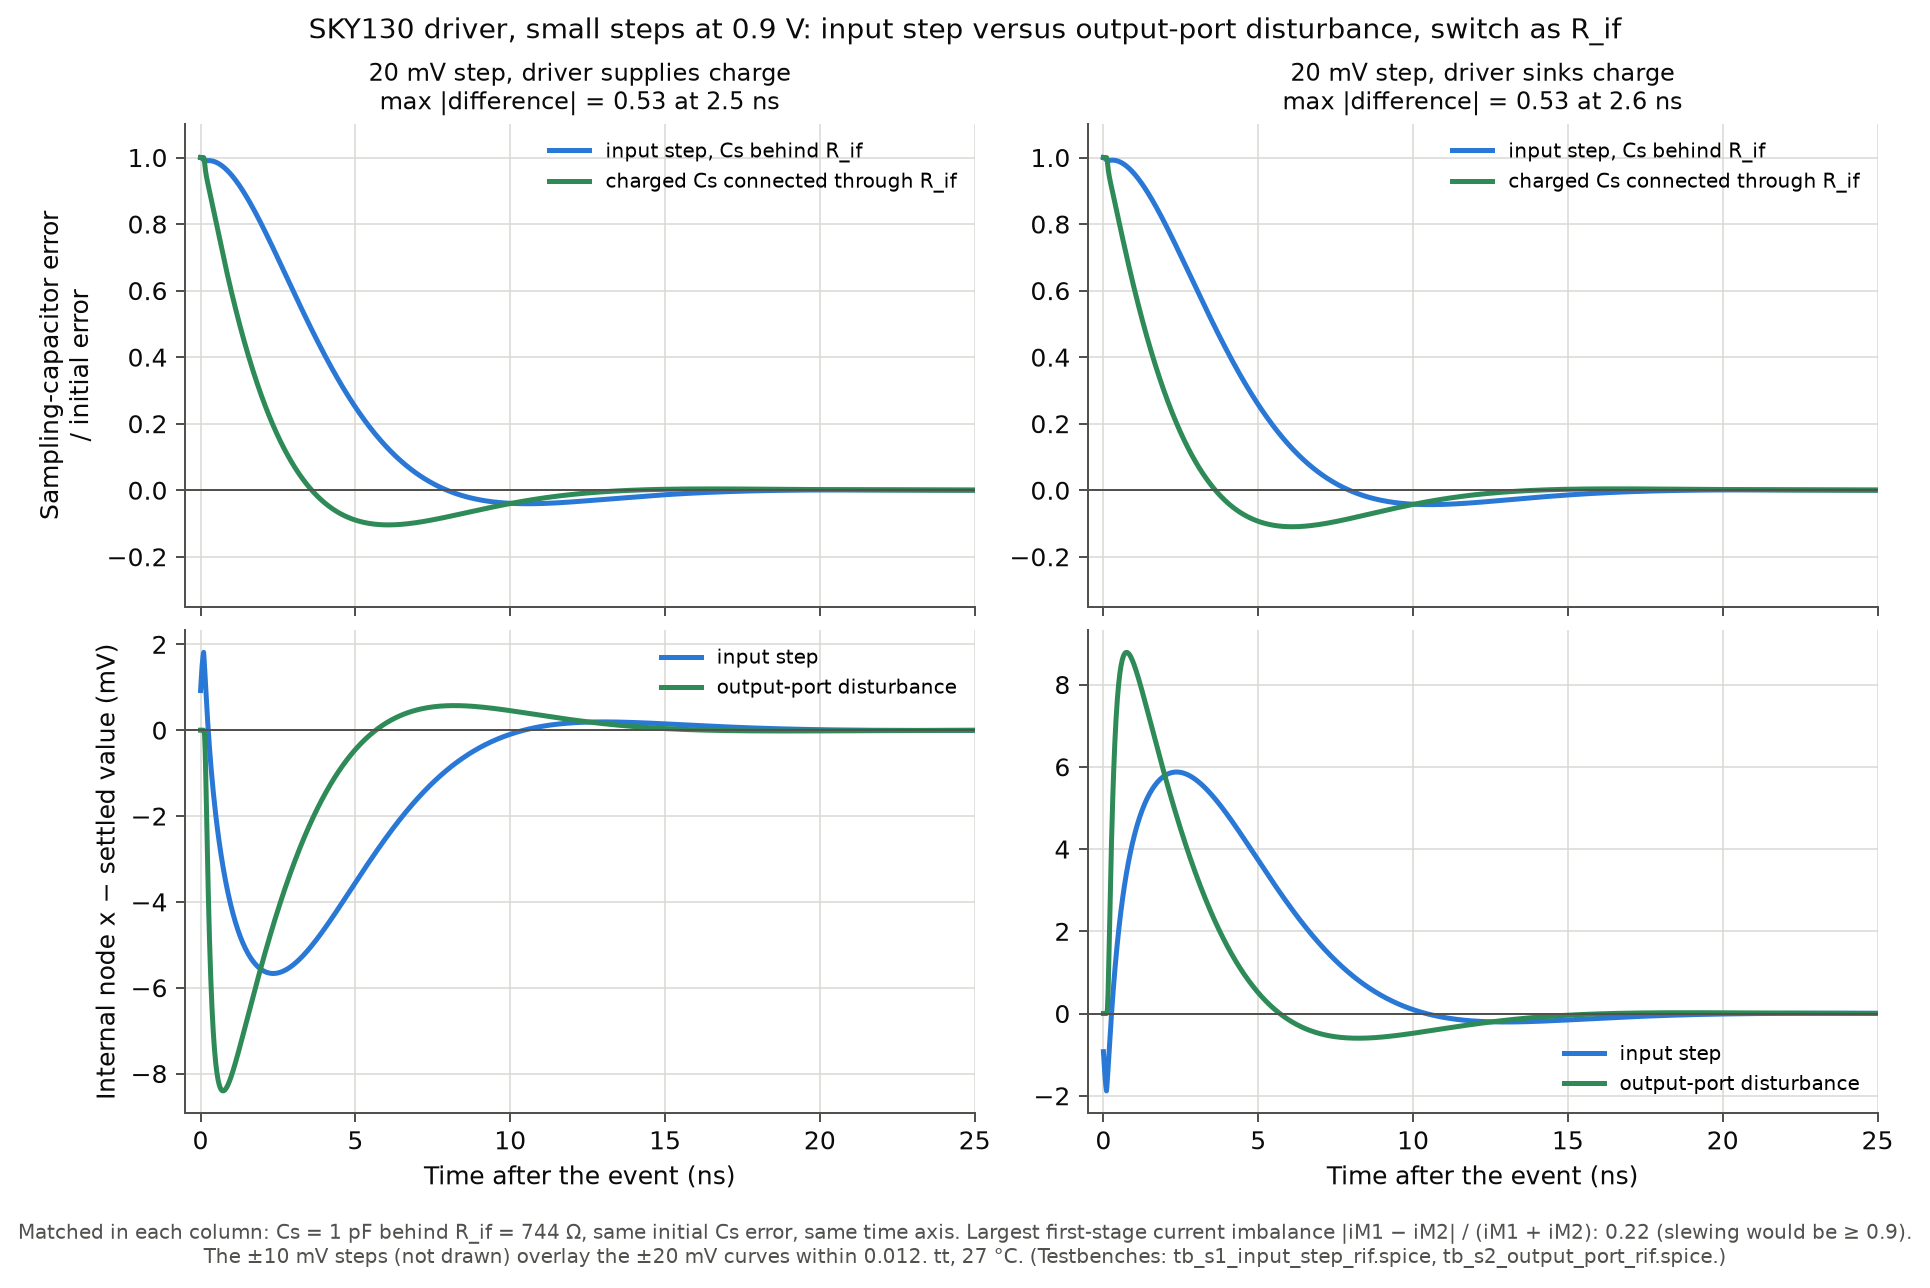

In [11]:
show("figure_sky130_small_step_ports")

*Figure 7. First-cut driver, `tt`, 27 °C: normalized response to a small input step and to an output-port disturbance
of the same size, both through `R_if`. Same closed-loop poles, different excitation port.*

**What the final measurement counts.** The sequential bench runs full-scale alternation for accumulation, every
(previous, target) pair on a 0.1 V grid, a 50 mV staircase in both directions, and a three-level sequence containing
every combination of the two preceding samples.  The held
value is read in the two windows of Section 2, so droop and coupling of the next command are included. The error is referred to the command. At
each PVT condition and for each read window, an offset and a gain error are taken from repeated samples at 0.6 V
and 1.2 V and removed by a terminal two-point line, by analogy with terminal-based gain and offset in ADC testing
(IEEE, 2011); the same line is applied to every sequence and previous state at that condition. The first
cycle after start-up is excluded. The design passes if the largest residual magnitude over all counted cycles,
both windows, and every condition of the declared set is at most `VLSB`. Calibrating once at nominal instead would
turn the offset and gain drift over PVT (about 2–6 mV of offset for the designs here) into error. 

For diagnosis, the measurement splits the corrected residual into three measured components: `r_S` immediately
before opening, `r_P` for the increase from pre-opening to early hold, and `r_H` for the increase from early to late
hold. Thus the early- and late-window residuals are `r_E = r_S + r_P` and `r_L = r_S + r_P + r_H`. There is no
independently measured final `r_A`: acquisition/history remaining before opening is included in `r_S`, and history
dependence is additionally diagnosed by its spread across previous states. Next-command coupling before the early
window is included in final `r_P`, which is not an isolated turn-off measurement. This measured decomposition is
distinct from the four-part provisional allocation (`R_S`, `R_P`, `R_A`, `R_H`) of Figure 3.

Because the dominant mechanisms have their worst cases at different corners (Section 3.2), and because process
corners represent global (die-to-die) variation and say nothing about mismatch (McConaghy et al., 2013),
the final PVT set is not pruned: five process corners × three supplies × three temperatures, each with all four
sequences, at 1.60, 1.80, and 1.95 V, matching SkyWater's 1.8 V model-validity limit and standard-cell characterisation
supplies (SkyWater Technology Foundry and Google, 2020) (Appendix B). Clock edges, phase skew, bias current, and `Cs` were held at their nominal values in this verification. 

Five further checks decide whether a pass is credible enough to freeze. **Numerics:** with the bootstrapped
switch, a 10 ps maximum step and `reltol` = 1e-4 produced 0.1–0.14 mV jumps between neighbouring levels at cold
corners, comparable to the effect being measured, so every closure run uses 5 ps and 1e-5 (Vogt et al., 2024); for the first-cut transmission gate this setting agreed with finer ones within 0.003 mV, and for the bootstrapped switch it removed 0.1 mV artefacts of coarser settings. A condition whose margin is smaller
than the numerical change is unresolved, not a pass.

**Stability** requires phase margin ≥ 45° and gain margin ≥ 10 dB under both the acquisition load (switch on,
`Cs`) and the hold load (switch off), no ringing above 0.1 `VLSB` in either read window, and, as a design target,
at least 50 mV from the triode edge (`vds − vdsat`) for every driver transistor that is not diode-connected; a
smaller corner margin is accepted only if the device stays saturated, the mechanism is understood, and the parent
contribution stays small.

**Noise:** the variance of one held sample equals the variance of the track-mode voltage on `Cs` when the switch
opens *(Established)* (Carusone et al., 2012), so the track-mode noise is integrated from 1 mHz (standing
in for a calibration interval) to 50 GHz. The SKY130 model gives only about 0.81–0.83 `kT/C` for the switch at zero
drain-source voltage, where a passive conductance must give exactly `kT/C`, so the switch is counted as exactly
`kT/C`. A result within 3 µV of the limit is unresolved.


Device-limit checks require every steady-state gate-source, gate-drain, and drain-source voltage to stay within
1.95 V. The gates of the bootstrapped switch and its booster devices exceed `VDD` relative to the substrate (up
to about 3.9 V) while their channels are inverted, which is the normal operating mode of this circuit, and its
transient excursions above 1.95 V are reported with peak and duration as limitations. The body-source voltages
of the booster devices must stay inside the model range, or those devices' bodies must be tied to their sources
in an isolated p-well.  

**No cancellation:** the certificate uses `M = max|r_S| + max|r_P| + max|r_H|` at each condition. The maxima may
occur on different samples, so `M` bounds the paired quantity
`Q = max_k(|r_S[k]| + |r_P[k]| + |r_H[k]|)`, with `Q <= M`. If `M <= VLSB`, a PASS does not rely on cancellation.
If `M > VLSB`, paired/pointwise analysis is required before cancellation reliance can be concluded. If that analysis
establishes reliance, the sign relationship must be checked over all 45 conditions, with clock-edge sensitivity and
mismatch analysis added.

The selected design was then run through the declared final PASS set: 5,490 counted samples over
45 conditions in four sequences, plus the stability, noise, and device-voltage checks (Table
3.5, Figure 8).

In [12]:
rows = ["| check | declared criterion | result | verdict |",
        "|---|---|---|---|"]
for c in final["checks"]:
    cells = [str(c[key]).replace("|", r"\|")
             for key in ("check", "criterion", "result", "verdict")]
    rows.append("| " + " | ".join(cells) + " |")
display(Markdown("\n".join(rows)))

| check | declared criterion | result | verdict |
|---|---|---|---|
| parent residual, primary timing, 45 conditions × 4 sequences (5490 counted samples), early and late windows | max\|r\| ≤ 1 LSB | 0.146 LSB at fs_1.60V_+125C | PASS |
| 25 mV levels at 4 conditions | max\|r\| ≤ 1 LSB | 0.128 LSB at fs_1.60V_+125C | PASS |
| driver loop, 135 condition/level points, acquisition and hold loads | PM ≥ 45°, GM ≥ 10 dB | PM ≥ 66.3°, GM ≥ 14.4 dB | PASS |
| driver saturation margins vds − vdsat (all non-diode-connected devices) | design target ≥ 50 mV; bounded worst-corner reduction allowed if still saturated | min 31 mV (xm2, sf_1.60V_+125C, 1.2 V); 2 point(s) below 50 mV — input pair at the top of the range, 1.60 V supply; still saturated | PASS (bounded corner reduction) |
| ringing in the read windows (peak-to-peak) | ≤ 0.1 LSB | 0.000 LSB | PASS |
| sampled noise, 90 condition/level points (switch exactly kT/C, 1 mHz–50 GHz) | ≤ 146 µV rms (unresolved within 3 µV) | 136.4 µV (0.233 LSB) at ff_1.95V_+125C, 1.2 V | PASS |
| no-cancellation certificate (M = sum of component maxima) | M ≤ 1 LSB; otherwise paired/pointwise analysis required | max M 0.169 LSB; certified at every condition | PASS |
| STRESS timing (full-scale command step at switch closure) | diagnostic | 2.0–11.6 LSB (sf_1.60V_+125C worst) | reported |
| switch terminal voltages, steady (end of each clock phase) | \|VGS\|,\|VGD\|,\|VDS\| ≤ 1.95 V (model validity) | max 1.950 V (MB0 vgs, fs_1.95V_-40C) | PASS |
| switch NMOS body-source voltage | within the model range, ≥ −1.95 V | min -1.950 V | PASS |
| switch terminal voltages, transient | reported limitation | peak 2.41 V (MXS vgs, fs_1.95V_+27C); longest above 1.96 V 0.20 ns/cycle (MTN vgs) | reported |

*Table 3.5. Final verification of the selected design against criteria declared before the result was assembled.
"Reported" rows are diagnostics, not pass/fail items.*

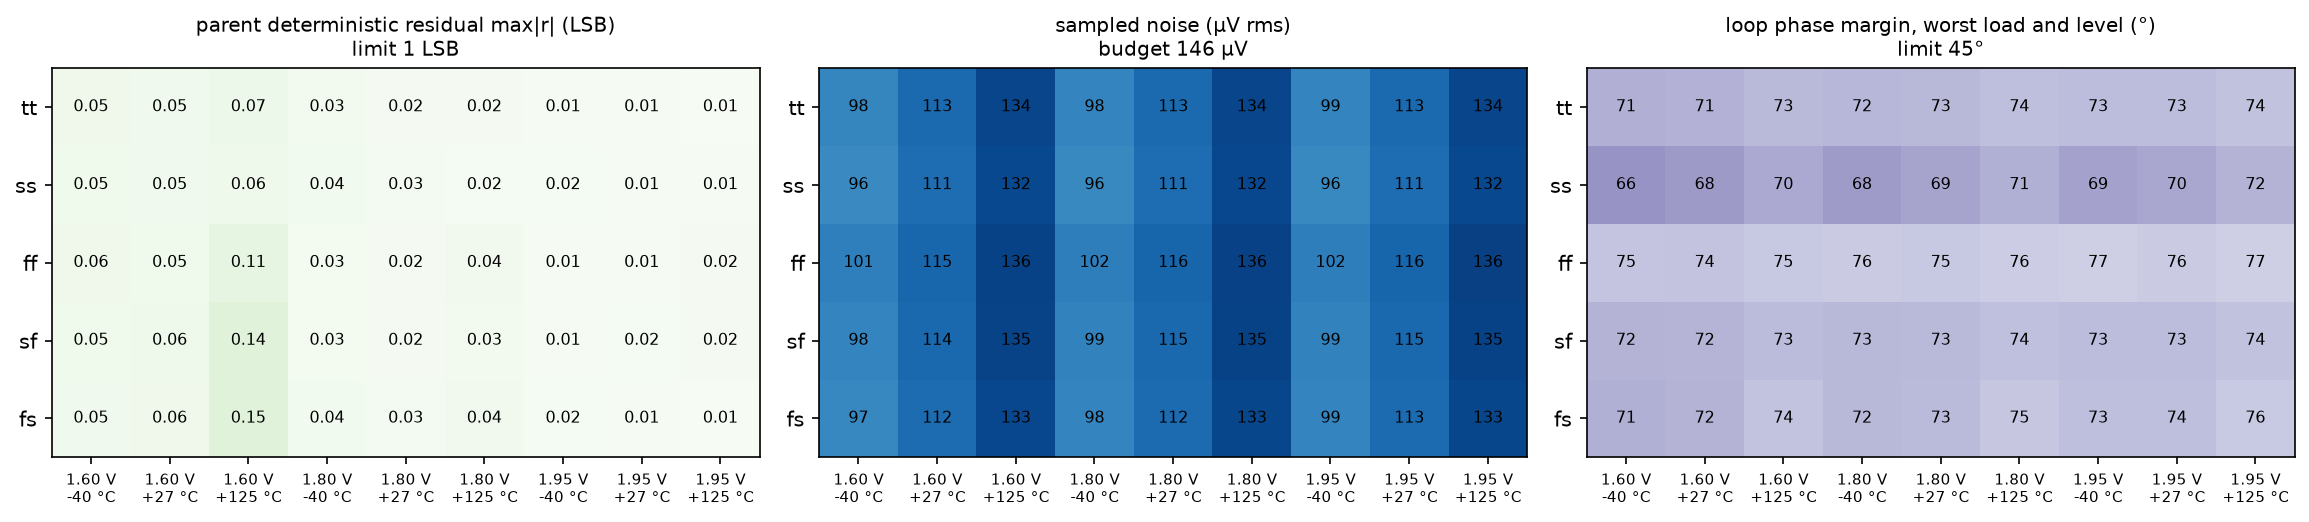

In [13]:
show("figure_closure_matrix")

*Figure 8. Final closure matrix over process corner × supply × temperature: largest parent residual (in `VLSB`, limit
1), largest sampled noise of the two input levels (µV rms, budget 146 µV), and the smallest driver phase margin over the
three input levels and both loads (limit 45°).*

The worst parent residual is 0.15 `VLSB` at fs_1.60V_+125C; every condition satisfies the conservative
no-cancellation certificate. The final design was not rerun at finer settings; the 5 ps / 1e-5 default was chosen because it removed the 0.1 mV step artefacts that coarser settings produced with the bootstrapped switch. Levels on a 25 mV grid at the worst conditions give at most 0.13 `VLSB`. The full-scale step at switch closure, now a diagnostic, gives
2.0–11.6 `VLSB`: with the larger `Cc` that the noise budget required, the driver does
not settle such a step within 40 ns (Section 3.6). The bootstrapped switch keeps every steady-state gate-source,
gate-drain, and drain-source voltage within 1.95 V; during switching some reach 2.41 V for well under a
nanosecond per cycle, which is reported as a limitation, not checked against a reliability rule.

On that evidence the design is frozen: it closes the declared deterministic requirement and the random-noise
budget, with a stable driver, over the declared schematic-level verification domain. This is not production
sign-off; mismatch, layout parasitics, and silicon are outside that domain (Appendix C).

### 3.6 Keep the loop closed across boundaries

Engineers divide a coupled circuit into blocks so that not every variable has to be solved at once, and they reuse
blocks. A block's result holds under conditions that circuits on the other side of the boundary supply, so a
boundary creates obligations: a representation of the neighbour adequate for the decisions made against it
(Section 3.3), applicability conditions — load, timing, range, supply, calibration — recorded where the integrator
will see them, a connected test for whatever the representation omits, reassessment on reuse as reuse and
systems-engineering practice require for heritage items in a new environment (Keating and Bricaud, 2002; NASA, 2016), and a named owner for each check in the verification plan, because an assumption that lives
only in one designer's testbench has not crossed the interface (Kundert et al., 2000; Kundert, 2003).

Figure 9 shows three places to draw the boundary in the running example. In scope A, driver, switch, and `Cs` are
one problem: switch width, driver current, and clock can be chosen against the parent residual at once, but the
driver cannot be reused or verified without this switch. In scope B, the boundary sits before the switch: the
driver can be characterized and reused on its own, provided the representation of the sampling network carries
every switch property that matters. The first cut's `R_if` and 1 kΩ allocation came from scope B, and both problems
found there — a representation without the turn-on event, and an allocation that sized the switch for settling
alone — concern what crossed that boundary. In scope C, the switch is inside the driver's block; the turn-on event
becomes internal, and any change of switch requires a new characterization of the whole block.

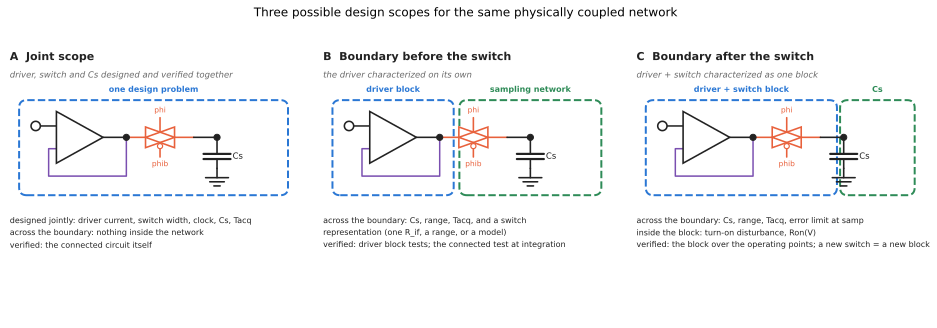

In [14]:
diagram("design_scopes")

*Figure 9. Three design scopes for the same network. A: joint; B: boundary before the switch, with an interface
representation of the sampling network; C: boundary after the switch. They differ in search size, interface content,
reuse, independent characterization, and who verifies the connection.*

The selected design is verified only under the conditions of Table 3.6, and they must travel with it.

| Condition the closure depends on | Declared verification range |
|---|---|
| sampling capacitance | `Cs` = 1 pF |
| clock | complementary phases, 0.2 ns edges |
| timing | 100 ns period, 40 ns acquisition, 60 ns hold |
| command timing | command changes during the hold (1 ns after opening); a full-scale change at switch closure is reported as a diagnostic only: 2.0–11.6 `VLSB`, not supported |
| supply and temperature | grid of 1.60, 1.80, 1.95 V × −40, 27, 125 °C × five process corners |
| calibration | two-point offset/gain correction at each operating condition, from repeated samples at 0.6 V and 1.2 V |
| read time | early window 10–20 ns after opening; late window up to 1 ns before the next acquisition |
| bias reference | 10 µA |
| random noise | 136 µV rms worst against 146 µV (0.25 `VLSB` rms) |
| not covered | mismatch, layout extraction, transistor-level clock drivers; ideal supply and ground, bias reference, and passives |

*Table 3.6. What travels with the block: the declared conditions of the final verification; results in Section 3.5.*


Each row is an obligation for whoever integrates the block. A downstream circuit that reads the sample later than
the late window, a calibration done once at nominal, or a command that steps at switch closure puts the block
outside its verified conditions. Reuse with a different switch is a new composition: the bootstrapped switch draws
a turn-on charge from the driver that grows with input voltage (about 20–30 fF times the input for the selected
size), unlike the transmission gate's kick, so the driver's settling result does not carry over unchanged. In each
case the obligation is a named test — the sequential bench at the affected conditions.

Organization research relates an organization's communication structure to the structure of the systems it
designs, and empirical work finds such mirroring in product and software development (Conway, 1968; MacCormack et al., 2012). In analog work this suggests *(Reflection)* that circuit, IP, and team
boundaries can shape one another whether or not the electrical coupling is weak there: under scope B the driver and
switch owners can both have correct results, and the connected test belongs to neither unless the plan assigns it.

## 4. What changes when AI enters the loop?

Sections 1–3 separate why the design was difficult from the practices that made it tractable. AI raises a
separate question for each.

### 4.1 Does AI change why analog design is difficult?

Mostly not. The switch still releases channel charge that depends on the signal level and the supply; the driver
still has finite gain, a finite output current, and a loop whose output the switch and capacitor load during
acquisition; the held voltage still becomes the next sample's starting point; process, supply, and temperature
still move every one of these; models still omit effects that only appear at a lower level of description. The
transmission gate's conduction gap at cold, low supply, the driver's tail leaving saturation at a 0.6 V input, and
the bootstrap's previous-sample dependence (Sections 3.2 and 3.3) are properties of the circuit, not of who, or
what, is running the design loop. An AI system that sizes this circuit faces the same coupled network as Figure 1.

The need for evidence does not disappear either. A tool that proposes a design produces a claim, and the claim
is only as good as the verification behind it. The one long-horizon agent study in the literature cited here, a
SKY130 SAR ADC built by language-model agents through post-extraction checks, reports that the agents sometimes
declared passes that were false (Yoshioka, 2026) (preprint).

### 4.2 Does AI change how engineers make the difficulty tractable?

Some difficulty came from physics; some came from the cost of handling coupled quantities together: the number
of conditions a person can simulate, read, and understand in a day; the number of knobs a person can move
jointly; the cost of coordinating the people who own the driver, the switch, and the verification. Allocations,
interface representations, and block boundaries exist partly because of that cost (Section 3.6). In this design
the 1 kΩ on-resistance allocation and the `R_if` representation let the driver and the switch be designed
separately, and both later proved inadequate for a decision they were used for (Sections 3.3 and 3.4). *(Interpretation.)*

Current peer-reviewed tools automate bounded parts of the loop: op-amp design on a defined benchmark with a
domain-specific language model (Chen et al., 2024), PVT-aware sizing with model-based reinforcement learning
that keeps corners inside the optimisation loop (Ahmadzadeh et al., 2026), multi-agent analysis and design
with tool use (Shen et al., 2026), and interactive layout through tool calls (Liu et al., 2025).
*(Established for those tasks; nothing more general is claimed.)*

*(Reflection from here to the end of 4.2.)* If such tools make a larger coupled region cheap to design, search,
and verify jointly, some boundaries that exist mainly for human tractability can move. In this circuit, driver
compensation, switch structure, `Cs`, clock sequence, and the sequential verification could be one search rather
than three owners connected by allocations — scope A of Figure 9 rather than scope B. The allocation split of
Section 3.1 would then matter less as a division of work and more as a diagnostic.

Other boundaries exist for reasons that do not depend on search cost, and they are likely to stay:

- **independent verification**: a result checked by a different tool, model, or person than the one that produced it —
  the reported false passes make this concrete, and here the sequential bench found a previous-sample error that a
  precharged fixture cannot show by construction;
- **reuse**: a block with a stable interface that serves several products, carrying conditions such as those of
  Table 3.6;
- **physical isolation**: between a noisy domain and a sensitive input, or between supplies;
- **measurement access**: a boundary at a node that can be probed on silicon;
- **fault containment** and **responsibility**: someone must answer for a requirement.

### 4.3 More search does not repair a wrong objective

Section 3 contains three concrete cases. The width ladder ranked the narrowest gate first by the local turn-off
share and below the half- and quarter-width gates by the parent residual; at cold, low-supply corners the
transmission gate stopped conducting at full and half width, so a narrower gate cannot conduct there either
(Derived). A search given the `R_if` representation as its model would have accepted 0.8 ns of acquisition in the
zero-step case where the connected circuit needs 10.3 ns (Section 3.3). And a search given only the nominal corner
as its verification domain would have kept the half-width gate, whose residual at `ss`, −40 °C, 1.62 V was 296
`VLSB` (Section 3.4). In each case, more search against the same objective, model, or domain does not resolve the
conflict. Closure required evaluating designs against the parent metric on repeated samples over PVT and changing
the circuit (Section 3.4). Optimization acts on the objective it is given. *(Interpretation of Observed results.)*

Stating the parent requirement, choosing the conditions over which it must hold, deciding which representation
is adequate for which decision, planning verification, diagnosing a failure, noticing when a pass depends on a
cancellation, and judging when the evidence is enough to freeze are themselves tasks that AI systems may
increasingly take on. Nothing here argues that these judgments are inherently human. What the eventual division
of work between people and AI will be, as development processes are rebuilt around AI, is not known.

To direct or check this work, an analog engineer needs to understand what these practices are for. An
allocation, a model, a test, a boundary, or a review each exists to control a particular physical or design
difficulty, and each introduces an assumption. Knowing both is what supports decisions about when to direct, check,
or rely on the work, whoever or whatever performs it. Section 5 lists those skills.

## 5. What an analog designer needs to learn

Circuit theory is necessary. Every step of this notebook used it: the on-resistance of a switch, the charge it
releases, the error of a follower, the headroom of a differential pair, the stability of a two-stage loop. The
textbook equations alone did not say that an acquisition allocation could pass at every nominal test point while
the held sample failed, that the worst condition would differ from one mechanism to the next, that one resistor could stand in for
the switch in one decision and not in another, or that a dummy switch would make the parent result worse. The
sample-and-hold also required the following skills.

| Skill | Where it appeared |
|---|---|
| Formulate an incomplete problem without pretending it is final, and know the role each quantity plays in it and what evidence may revise it | 3.1 |
| Relate local decisions to the parent: one knob moves several quantities, which reach the parent as a signed sum, so a local metric can pass, or rank designs, differently | 1, 3.2, 3.4 |
| Characterize where a result holds, over operating point, previous state, timing, and PVT, rather than quoting one number | 3.2 |
| Choose a model or test that is adequate for the decision at hand, and notice when it is not | 3.3, 3.5 |
| Revise at the level the evidence points to, including changing the circuit so that a dependency weakens instead of retuning a value | 3.4 |
| Judge when evidence is sufficient to freeze a design, and say what it does not cover | 3.5 |
| Keep the obligations a boundary creates attached to the block when it is reused or integrated | 3.6 |

None of these replaces knowing how a circuit works; each is a way of using that knowledge on a problem whose
requirements are provisional and whose physics is coupled. As AI systems take over more of the search,
simulation, sizing, layout, and possibly the judgments themselves, these skills are what let an engineer decide
— or check how a tool decided — what problem to solve, which results need independent checking, and when a pass
is enough. Whatever tools are used, the designer must understand the problem being solved and why the evidence
for the answer can be trusted.

## Appendix

### A. Reproducing and rerunning

Everything in this notebook is regenerated with open-source tools. Tested versions: ngspice-42; SKY130A from
open_pdks commit `c6d73a35f524070e85faff4a6a9eef49553ebc2b` (installed with volare); Python 3.14.6 with the
packages pinned in `uv.lock` (uv project; Python ≥ 3.12 required).

```bash
uv sync --locked                        # Python environment from pyproject.toml + uv.lock
export PDK_ROOT=$HOME/.volare           # location of sky130A (e.g. installed with volare)
uv run python scripts/reproduce.py --no-spice    # figures and notebook from the committed results (minutes)
uv run python scripts/reproduce.py --skip-final  # all simulations except the final closure verification
uv run python scripts/reproduce.py               # everything, including the final closure verification
```

| Result | Script | Outputs |
|---|---|---|
| first-cut evidence (Figures 5–7; Sections 3.2–3.5) | `experiments/experiment_a/sky130/run_sky130.py`, `run_followup.py`; reduced model `experiments/experiment_a/ideal/run_experiment.py` | `results/data/`, `results/figures/figure_sky130_*`, `figure_reduced_model_*` |
| first cut on the sequential bench (Figure 4) | `experiments/closure/run_screen.py f2 --pvt screen --legacy` (screening definitions before the final-verification amendments) | `results/closure/screen/f2_screen.json` |
| final closure verification (Section 3.5, Figure 8) | `experiments/closure/run_final.py q1_boot2`, then `assemble_final.py q1_boot2` | `results/closure/final/q1_boot2/*.json`, `results/figures/figure_closure_matrix.*` |
| explanatory diagrams (Figures 1–3) | `scripts/draw_restart_diagrams.py` | `assets/diagrams/*.svg` |

The two "Try it" cells read `results/data/sky130_waveforms_tt.csv` and `results/data/sky130_followup_summary.json`;
with `SOURCE = "spice"` they rerun only their first-cut benches through
`experiments/experiment_a/sky130/interactive.py`, writing to a temporary folder. The cell below re-simulates one
nominal case of the selected design on the sequential bench.

In [15]:
# Optional: re-simulate one nominal case of the selected design on the
# sequential bench (requires ngspice and SKY130A; a few minutes).
# Set RUN_SPICE = True here, or execute the notebook with the environment
# variable RUN_SPICE=1. Edit the design in experiments/closure/designs.py
# (or pass another PVT) to see the parent residual move.
RUN_SPICE = os.environ.get("RUN_SPICE", "0") == "1"
if RUN_SPICE:
    sys.path.insert(0, str(REPO / "experiments" / "closure"))
    import designs
    import parent_metric as pm
    import shbench as sb
    r = pm.evaluate_many(designs.DESIGNS["q1_boot2"],
                         [sb.PVT("tt", 1.80, 27)],
                         include=("cal_alt", "pair"))[0]
    print(f"{r['tag']}, cal_alt + pair: "
          f"max|r| = {r['max_abs_r_LSB']:.3f} LSB, "
          f"supply current {r['supply_current_uA']:.0f} µA")
else:
    print("skipped: set RUN_SPICE = True to re-simulate one nominal case "
          "(requires ngspice and SKY130A)")

skipped: set RUN_SPICE = True to re-simulate one nominal case (requires ngspice and SKY130A)


The pre-registered parent metric, budget, verification sets, and every amendment made before final verification
are in `experiments/closure/CLOSURE_BRIEF.md`; the sequential bench is `experiments/closure/shbench.py`, the metric
`parent_metric.py`, and the stability, noise, and device-limit checks `stability.py`, `noise.py`, and `run_final.py`.
The first-cut experiment definition is `experiments/experiment_a/sky130/DESIGN_BRIEF.md`.

### B. Supporting design details

The selected design, as summarized from the final result and as simulated:

In [16]:
d = final["design_summary"]
rows = ["| item | value |", "|---|---|"]
rows += [f"| {k} | {v} |" for k, v in d.items()]
display(Markdown("\n".join(rows)))

| item | value |
|---|---|
| driver | folded-cascode first stage (native-threshold NMOS pair), PMOS common-source second stage, Miller Cc + Rz, output capacitor; bias lines RC-filtered |
| sampling switch | bootstrapped NMOS (W 2 µm, L 0.15 µm), bootstrap capacitor 0.2 pF, clock-boosted charging device |
| Cs | 1 pF |
| clock | two complementary phases, 0.2 ns edges, 100 ns period, 40 ns acquisition |
| supply current | 785 µA at tt (max 979 µA over the declared set) |
| devices | driver 22 transistors, switch 12 |
| ideal passives in the driver | CC=5p CF3=2p CF4=2p CF1=2p CF2=2p CO=4p CF5=2p; RZ=0.3k RF3=100k RF4=100k RF1=100k RF2=100k RF5=100k |

In [17]:
# the selected driver and sampling switch as simulated
# (ideal elements are listed in each header)
for f in ("driver_drv_Q1.spice", "sw_bootab.spice"):
    t = (REPO / "experiments" / "closure" / "netlists" / f).read_text()
    print(t[t.index(".subckt"):t.index(".ends") + 5], "\n")
print("selected switch instance parameters "
      "(overriding the defaults above):", final["switch_params"])

.subckt drv_Q1 vcmd fb out ibias vdd vss
* reference (Iref = 10 uA sunk into ibias) and NMOS bias sinks, 10 uA each
XM8  ibias ibias vss vss sky130_fd_pr__nfet_01v8 W=4 L=1 m=1
XM18 vbp   ibias vss vss sky130_fd_pr__nfet_01v8 W=4 L=1 m=1
XM21 vbpc  ibias vss vss sky130_fd_pr__nfet_01v8 W=4 L=1 m=1
* PMOS bias: vbp diode; PMOS copies feeding the vbnc diode and the output-sink diode; vbpc diode
XM17 vbp   vbp   vdd vdd sky130_fd_pr__pfet_01v8_lvt W=20 L=0.5 m=1
XM20 vbnc  vbp   vdd vdd sky130_fd_pr__pfet_01v8_lvt W=20 L=0.5 m=1
XM22 vbnc  vbnc  vss vss sky130_fd_pr__nfet_01v8 W=1 L=2.5 m=1
XM19 vbpc  vbpc  vdd vdd sky130_fd_pr__pfet_01v8_lvt W=1.65 L=1 m=1
XM23 ib2   vbp   vdd vdd sky130_fd_pr__pfet_01v8_lvt W=20 L=0.5 m=1
XM24 ib2   ib2   vss vss sky130_fd_pr__nfet_01v8 W=2.5 L=4 m=1
* tail and native-threshold input pair
XM5  tail  ibt   vss vss sky130_fd_pr__nfet_01v8 W=4 L=1 m=17
XM1  f1    fb    tail vss sky130_fd_pr__nfet_03v3_nvt W=4 L=0.5 m=8
XM2  f2    vcmd  tail vss sky130_fd_p

The driver responses compared before the final refinement (Section 3.4):

| Driver response | Current at `tt` | What it improved | What it cost or missed |
|---|---:|---|---|
| Two-stage, mirror-loaded first stage (first cut) | 130 µA | fast; noise ≈ 263 µV at `tt` | pre-opening residual up to 1.03 mV at the `fs` corners (tail in triode; measured with the first-cut gate) |
| Folded-cascode first stage, native pair, separate sink bias | 288 µA | pre-opening residual ≤ 0.022 mV; screening ≤ 0.27 `VLSB` (primary timing) and ≤ 0.42 `VLSB` (stress timing) | noise ≈ 745 µV at `tt`* |
| Single-stage, load-compensated, gain-boosted folded cascode | 272 µA | screening ≤ 0.50 `VLSB` in the primary timing at a third of the selected driver's current | noise 123–234 µV over the screened conditions*, above budget at `tt`; stress timing up to 42.7 `VLSB` |

*Table B.1. Driver responses with the bootstrapped switch (5 µm), `Cs` = 1 pF, 40 ns, on the sequential bench at the
screening conditions of that stage (supplies 1.62/1.80/1.98 V). Noise is rms on `Cs`, budget 146 µV. \*Earlier noise
method (1 kHz lower bound, switch as modelled); the correction of Section 3.5 changes these figures by a few µV.
Source: `results/closure/candidates/table34.json` (`experiments/closure/table34_evidence.py`).*

Three decisions were recorded before final verification. The supplies moved from 1.62 and 1.98 V to 1.60 and
1.95 V, because SkyWater publishes the 1.8 V MOS models as valid up to 1.95 V and characterises its 1.8 V standard
cells at 1.60 V and 1.95 V (SkyWater Technology Foundry and Google, 2020). Stress timing, a full-scale command step coincident with
switch closure, moved from the pass/fail set to a reported diagnostic, because the frozen parent function specifies
a command that changes during the hold; the parent requirement, range, acquisition time, and PVT set were not
changed. For random noise, one final refinement toward 146 µV was allowed, with a single fallback to `VLSB/√12` ≈
169 µV, the quantization-noise equivalent of a 10-bit step, if it missed; it did not miss. 

### C. Scope and provenance

The selected design is a defensible point within the explored design space, not a global optimum, and the closure
is schematic-level, not production sign-off. Specifically:

- Device mismatch, layout extraction, aging, package, and silicon are not covered. Mismatch offset is removed by the
  two-point correction, but its effect on the level-dependent residual is not simulated.
- Clock drivers are ideal ramps; the bias reference, the compensation and filter resistors and
  capacitors, the output capacitor, the bootstrap capacitors, and `Cs` are ideal elements, so PDK resistor and
  capacitor corners are not applied. The noise analysis excludes the bias reference and the clocks.
- The requirement assumes a two-point calibration at each operating condition, and covers the primary command
  timing; a full-scale step at switch closure is a reported diagnostic.

- Gate voltages of the bootstrapped switch exceed `VDD` relative to the substrate while the channel is inverted, and some
  terminal voltages exceed 1.95 V briefly during switching; no oxide or hot-carrier reliability claim is made.
- The driver's input-pair saturation margin narrows to 31–33 mV at one condition against the 50 mV design target
  (Section 3.4), with the device still saturated.
- Level coverage is a set of representative grids (0.1 V pairs, 50 mV and 25 mV staircases), not a continuous sweep.

The circuit was designed from scratch for this notebook and does not reproduce any private design. AI-assisted
research, simulation scripting, design exploration, and writing tools were used during development; the author
selected the engineering questions, set and reviewed the requirements and decisions, and is responsible for the
final artifact.

## References

- **Abo and Gray, 1999** — Abo, Andrew M.; Gray, Paul R. (1999). *A 1.5-V, 10-bit, 14.3-MS/s CMOS Pipeline Analog-to-Digital Converter*. IEEE Journal of Solid-State Circuits, 34(5), 599–606. https://doi.org/10.1109/4.760369
- **Ahmadzadeh et al., 2026** — Ahmadzadeh, Mohsen; Lappas, Jan; Wehn, Norbert; Gielen, Georges G. E. (2026). *AnaCraft: Duel-Play Probabilistic-Model-Based Reinforcement Learning for Sample-Efficient PVT-Robust Analog Circuit Sizing Optimization*. IEEE Transactions on Computer-Aided Design of Integrated Circuits and Systems, 45(2), 901–914. https://doi.org/10.1109/TCAD.2025.3582175 (Published online 2 July 2025)
- **Black, 1934** — Black, H. S. (1934). *Stabilized Feedback Amplifiers*. Bell System Technical Journal, 13(1), 1–18. https://doi.org/10.1002/j.1538-7305.1934.tb00652.x
- **Carusone et al., 2012** — Carusone, Tony Chan; Johns, David A.; Martin, Kenneth W. (2012). *Analog Integrated Circuit Design*. Wiley, 2nd ed.
- **Chang and Kundert, 2007** — Chang, Henry; Kundert, Ken (2007). *Verification of Complex Analog and RF IC Designs*. Proceedings of the IEEE, 95(3), 622–639. https://doi.org/10.1109/JPROC.2006.889384
- **Chen et al., 2024** — Chen, Zihao; Huang, Jiangli; Liu, Yiting; Yang, Fan; Shang, Li; Zhou, Dian; Zeng, Xuan (2024). *Artisan: Automated Operational Amplifier Design via Domain-Specific Large Language Model*. Proceedings of the 61st ACM/IEEE Design Automation Conference (DAC), 39:1–39:6. https://doi.org/10.1145/3649329.3655903
- **Conway, 1968** — Conway, Melvin E. (1968). *How Do Committees Invent?*. Datamation, 14(4), 28–31. https://www.melconway.com/Home/Committees_Paper.html
- **Eichenberger and Guggenbühl, 1990** — Eichenberger, Christoph; Guggenbühl, Walter (1990). *On Charge Injection in Analog MOS Switches and Dummy Switch Compensation Techniques*. IEEE Transactions on Circuits and Systems, 37(2), 256–264. https://doi.org/10.1109/31.45719
- **Graeb, 2007** — Graeb, Helmut E. (2007). *Analog Design Centering and Sizing*. Springer. https://doi.org/10.1007/978-1-4020-6004-5
- **Gray et al., 2009** — Gray, Paul R.; Hurst, Paul J.; Lewis, Stephen H.; Meyer, Robert G. (2009). *Analysis and Design of Analog Integrated Circuits*. Wiley, 5th ed.
- **IEEE, 2011** — IEEE (2011). *IEEE Standard for Terminology and Test Methods for Analog-to-Digital Converters*. https://doi.org/10.1109/IEEESTD.2011.5692956 (superseded by IEEE Std 1241-2023)
- **Keating and Bricaud, 2002** — Keating, Michael; Bricaud, Pierre (2002). *Reuse Methodology Manual for System-on-a-Chip Designs*. Springer, 3rd ed. https://doi.org/10.1007/b116360
- **Kundert et al., 2000** — Kundert, Ken; Chang, Henry; Jefferies, Dan; Lamant, Gilles; Malavasi, Enrico; Sendig, Fred (2000). *Design of Mixed-Signal Systems-on-a-Chip*. IEEE Transactions on Computer-Aided Design of Integrated Circuits and Systems, 19(12), 1561–1571. https://doi.org/10.1109/43.898832
- **Kundert, 2003** — Kundert, Ken (2003). *Principles of Top-Down Mixed-Signal Design*. ISSCC 2003 short-course paper / The Designer's Guide. https://kenkundert.com/docs/isscc03-paper.pdf (Tutorial/practitioner source; not a journal article)
- **Liu et al., 2025** — Liu, Bingyang; Zhang, Haoyi; Gao, Xiaohan; Kong, Zichen; Tang, Xiyuan; Lin, Yibo; Wang, Runsheng; Huang, Ru (2025). *LayoutCopilot: An LLM-Powered Multiagent Collaborative Framework for Interactive Analog Layout Design*. IEEE Transactions on Computer-Aided Design of Integrated Circuits and Systems, 44(8), 3126–3139. https://doi.org/10.1109/TCAD.2025.3529805
- **MacCormack et al., 2012** — MacCormack, Alan; Baldwin, Carliss; Rusnak, John (2012). *Exploring the Duality between Product and Organizational Architectures: A Test of the “Mirroring” Hypothesis*. Research Policy, 41(8), 1309–1324. https://doi.org/10.1016/j.respol.2012.04.011
- **McConaghy et al., 2013** — McConaghy, Trent; Breen, Kristopher; Dyck, Jeffrey; Gupta, Amit (2013). *Variation-Aware Design of Custom Integrated Circuits: A Hands-on Field Guide*. Springer. https://doi.org/10.1007/978-1-4614-2269-3
- **Mukherjee et al., 2000** — Mukherjee, Tamal; Carley, L. Richard; Rutenbar, Rob A. (2000). *Efficient Handling of Operating Range and Manufacturing Line Variations in Analog Cell Synthesis*. IEEE Transactions on Computer-Aided Design of Integrated Circuits and Systems, 19(8), 825–839. https://doi.org/10.1109/43.856971
- **NASA, 2016** — NASA (2016). *NASA Systems Engineering Handbook*. NASA, NASA/SP-2016-6105 Rev2. https://ntrs.nasa.gov/citations/20170001761 (Official agency handbook; systems-engineering domain, not analog IC design)
- **Razavi, 2015** — Razavi, Behzad (2015). *The Bootstrapped Switch [A Circuit for All Seasons]*. IEEE Solid-State Circuits Magazine, 7(3), 12–15. https://doi.org/10.1109/MSSC.2015.2449714
- **Razavi, 2017** — Razavi, Behzad (2017). *Design of Analog CMOS Integrated Circuits*. McGraw-Hill Education, 2nd ed.
- **Rutenbar et al., 2007** — Rutenbar, Rob A.; Gielen, Georges G. E.; Roychowdhury, Jaijeet (2007). *Hierarchical Modeling, Optimization, and Synthesis for System-Level Analog and RF Designs*. Proceedings of the IEEE, 95(3), 640–669. https://doi.org/10.1109/JPROC.2006.889371
- **Shen et al., 2026** — Shen, Jinyi; Chen, Zihao; Zhuang, Ji; Huang, Jiangli; Yang, Fan; Shang, Li; Bi, Zhaori; Yan, Changhao; Zhou, Dian; Zeng, Xuan (2026). *Atelier: An Automated Analog Circuit Design Framework via Multiple Large Language Model-Based Agents*. IEEE Transactions on Computer-Aided Design of Integrated Circuits and Systems, 45(1), 31–44. https://doi.org/10.1109/TCAD.2025.3573228 (Early-access DOI published in 2025)
- **Simon, 1962** — Simon, Herbert A. (1962). *The Architecture of Complexity*. Proceedings of the American Philosophical Society, 106(6), 467–482. https://www.jstor.org/stable/985254
- **SkyWater Technology Foundry and Google, 2020** — SkyWater Technology Foundry; Google (2020). *SkyWater SKY130 Open Source PDK documentation*. https://skywater-pdk.readthedocs.io/ (Models used here: SKY130A from open\_pdks commit c6d73a35f524070e85faff4a6a9eef49553ebc2b)
- **Smith and Eppinger, 1997** — Smith, Robert P.; Eppinger, Steven D. (1997). *Identifying Controlling Features of Engineering Design Iteration*. Management Science, 43(3), 276–293. https://doi.org/10.1287/mnsc.43.3.276
- **Steward, 1981** — Steward, Donald V. (1981). *The Design Structure System: A Method for Managing the Design of Complex Systems*. IEEE Transactions on Engineering Management, EM-28(3), 71–74. https://doi.org/10.1109/TEM.1981.6448589
- **Vogt et al., 2024** — Vogt, Holger; Atkinson, Giles; Nenzi, Paolo (2024). *Ngspice User's Manual, Version 42*. https://ngspice.sourceforge.io/docs.html
- **Wegmann et al., 1987** — Wegmann, George; Vittoz, Eric A.; Rahali, Fouad (1987). *Charge Injection in Analog MOS Switches*. IEEE Journal of Solid-State Circuits, 22(6), 1091–1097. https://doi.org/10.1109/JSSC.1987.1052859
- **Yoshioka, 2026** — Yoshioka, Kentaro (2026). *The Era of Vibe Tapeout: Dark Age or Golden Age for Analog Circuit Design?*. arXiv:2610.15240. https://doi.org/10.48550/arXiv.2610.15240 (Preprint; emerging frontier evidence, not a peer-reviewed Established anchor)

Source roles and the statement each source supports are recorded in `references/REFERENCE_MAP.md`.